In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from nilearn.datasets import fetch_atlas_harvard_oxford
from matplotlib import pyplot as plt
from scipy.stats import spearmanr
import json
from nilearn.plotting import plot_roi

In [2]:
config = json.load(open("../../config.json"))

In [3]:
CONDITIONS = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]
STIMULUS = {condition: condition.split("_")[0] for condition in CONDITIONS}
SESSION = {condition: condition.split("_")[1] for condition in CONDITIONS}


# These are the two conditions whose stimulus matches the deprived need.
MOTIVATIONALLY_RELEVANT = {
    "food_fasting",
    "social_isolation",
}

In [4]:
def clean_roi_name(roi):
    """
    Remove a trailing .nii from ROI names while preserving spaces,
    commas, apostrophes, and underscores.
    """
    roi = str(roi).strip()

    if roi.endswith(".nii"):
        roi = roi[:-4]

    return roi

In [5]:
df = pd.read_csv('../../results_MNI152NLin2009cAsym/rdms_thresh_80/rdm_metadata.csv')
df['roi'] = df['roi'].apply(clean_roi_name)
df


,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Subcallosal Cortex,True,305,0.932722,"['run1', 'run2', 'run5', 'run6']"
1,sub-SAXSISO01,SNc_VTA,True,21,1.000000,"['run1', 'run2', 'run5', 'run6']"
2,sub-SAXSISO01,"Cingulate Gyrus, anterior division",True,724,1.000000,"['run1', 'run2', 'run5', 'run6']"
3,sub-SAXSISO01,Caudate,True,303,1.000000,"['run1', 'run2', 'run5', 'run6']"
4,sub-SAXSISO01,Superior Frontal Gyrus,True,1657,0.980473,"['run1', 'run2', 'run5', 'run6']"
...,...,...,...,...,...,...
2363,sub-SAXSISO42,"Temporal Fusiform Cortex, posterior division",False,349,0.772124,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2364,sub-SAXSISO42,"Superior Temporal Gyrus, anterior division",True,165,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2365,sub-SAXSISO42,"Middle Temporal Gyrus, temporooccipital part",True,587,0.989882,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2366,sub-SAXSISO42,"Middle Temporal Gyrus, anterior division",True,228,0.923077,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"


In [6]:
# Lets add which dataset this roi came from so we wont mix them

midbrai_roi = roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "RN", "SNr", "PBP", "VeP", "HN", "HTH", "MN", "STH", "SNc_VTA"]

cortical_roi = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels
subcortical_roi = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

cortical_roi.remove("Background")
subcortical_roi.remove("Background")

subcortical_roi = [roi.removeprefix("Left ").removeprefix("Right ") for roi in subcortical_roi]

[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl


In [7]:
df['atlas'] = np.where(df['roi'].isin(cortical_roi), 'cortical', 
                       np.where(df['roi'].isin(subcortical_roi), 'subcortical', 
                                np.where(df['roi'].isin(midbrai_roi), 'midbrain', 'unknown')))

In [8]:
df.groupby('atlas')['roi'].nunique()

atlas
cortical       48
midbrain       15
subcortical    11
Name: roi, dtype: int64

In [9]:
df.query('included').groupby('atlas')['roi'].nunique()

atlas
cortical       47
midbrain       14
subcortical    11
Name: roi, dtype: int64

In [10]:
rdms = np.load('../../results_MNI152NLin2009cAsym/rdms_thresh_80/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile '../../results_MNI152NLin2009cAsym/rdms_thresh_80/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions)

In [11]:
display(
    df.query('included').groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .sort_values(['atlas', 'n_participants'])
)


,atlas,roi,n_participants
12,cortical,"Inferior Temporal Gyrus, anterior division",1
46,cortical,Temporal Pole,2
13,cortical,"Inferior Temporal Gyrus, posterior division",6
28,cortical,"Parahippocampal Gyrus, anterior division",7
44,cortical,"Temporal Fusiform Cortex, posterior division",15
...,...,...,...
66,subcortical,Cerebral White Matter,32
68,subcortical,Lateral Ventricle,32
69,subcortical,Pallidum,32
70,subcortical,Putamen,32


In [12]:
# looking at this we should exclude roi with little participants rdms

excluded_rois = (
    df.query('included')
    .groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .query('n_participants < 20')  # for example, exclude ROIs with less than 5 participants
)
excluded_rois

,atlas,roi,n_participants
12,cortical,"Inferior Temporal Gyrus, anterior division",1
13,cortical,"Inferior Temporal Gyrus, posterior division",6
28,cortical,"Parahippocampal Gyrus, anterior division",7
44,cortical,"Temporal Fusiform Cortex, posterior division",15
46,cortical,Temporal Pole,2


In [13]:
# Lets create model rdms

def make_pairwise_model(name, pair_function):
    """
    Construct a symmetric model RDM from a function that assigns a
    value to each pair of conditions.
    """
    model = pd.DataFrame(
        np.zeros((len(CONDITIONS), len(CONDITIONS))),
        index=CONDITIONS,
        columns=CONDITIONS,
        dtype=float,
    )

    for i, condition_1 in enumerate(CONDITIONS):
        for j in range(i + 1, len(CONDITIONS)):
            condition_2 = CONDITIONS[j]

            value = float(
                pair_function(condition_1, condition_2)
            )

            model.loc[condition_1, condition_2] = value
            model.loc[condition_2, condition_1] = value

    model.attrs["name"] = name
    return model


baseline_vs_deprived = make_pairwise_model(
    "baseline_vs_deprived",
    lambda a, b: (
        (SESSION[a] == 'baseline')
        !=
        (SESSION[b] == 'baseline')
    ),
)

isolation_vs_baseline_and_fasting = make_pairwise_model(
    "isolation_vs_baseline_and_fasting",
    lambda a, b: (
        (SESSION[a] == 'isolation')
        !=
        (SESSION[b] == 'isolation')
    ),
)

fasting_vs_baseline_and_isolation = make_pairwise_model(
    "fasting_vs_baseline_and_isolation",
    lambda a, b: (
        (SESSION[a] == 'fasting')
        !=
        (SESSION[b] == 'fasting')
    ),
)



social_vs_food_and_flowers = make_pairwise_model(
    "social_vs_food_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'social')
        !=
        (STIMULUS[b] == 'social')
    ),
)

food_vs_social_and_flowers = make_pairwise_model(
    "food_vs_social_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'food')
        !=
        (STIMULUS[b] == 'food')
    ),
)

flowers_vs_social_and_food = make_pairwise_model(
    "flowers_vs_social_and_food",
    lambda a, b: (
        (STIMULUS[a] == 'flowers')
        !=
        (STIMULUS[b] == 'flowers')
    ),
)


social_isolation_vs_rest_model = make_pairwise_model(
    "social_isolation_vs_rest",
    lambda a, b: (
        (a == 'social_isolation')
        !=
        (b == 'social_isolation')
    ),
)

food_fasting_vs_rest_model = make_pairwise_model(
    "food_fasting_vs_rest",
    lambda a, b: (
        (a == 'food_fasting')
        !=
        (b == 'food_fasting')
    ),
)

food_fasting_and_social_isolation_vs_rest = make_pairwise_model(
    "food_fasting_and_social_isolation_vs_rest",
    lambda a, b: (
        (a in ['food_fasting', 'social_isolation'])
        !=
        (b in ['food_fasting', 'social_isolation'])
    ),
)

In [14]:
#  Category-clustering models

    # 2.1 Stimulus family
        # social_vs_food_and_flowers
        # food_vs_social_and_flowers
        # flowers_vs_social_and_food

    # 2.2 Session family
        # baseline_vs_deprived
        # isolation_vs_baseline_and_fasting
        # fasting_vs_baseline_and_isolation

# Motivation deprivation models
    # social_isolation_vs_rest_model
    # food_fasting_vs_rest_model
    # food_fasting_and_social_isolation_vs_rest

MODEL_RDMS = {
    'Social cues vs. food and flower cues': social_vs_food_and_flowers,
    'Food cues vs. social and flower cues': food_vs_social_and_flowers,
    'Flower cues vs. social and food cues': flowers_vs_social_and_food,

    'Baseline vs. fasting and isolation': baseline_vs_deprived,
    'Isolation vs. baseline and fasting': isolation_vs_baseline_and_fasting,
    'Fasting vs. baseline and isolation': fasting_vs_baseline_and_isolation,

    'Social cues after isolation vs. all other conditions': social_isolation_vs_rest_model,
    'Food cues after fasting vs. all other conditions': food_fasting_vs_rest_model,
    'Deprivation-matched cues vs. all other conditions': food_fasting_and_social_isolation_vs_rest,
}

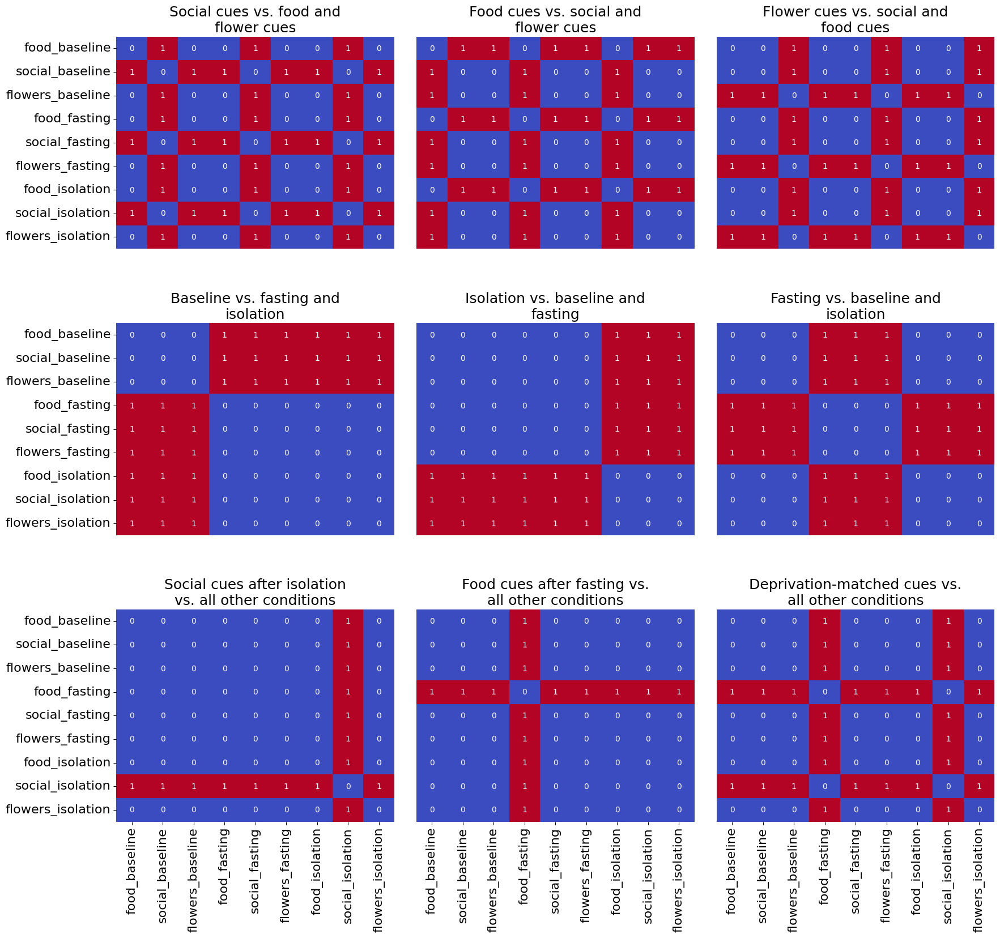

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

fig, axes = plt.subplots(3, 3, figsize=(20, 18), sharex=True, sharey=True)

for idx, ((name, rdm), ax) in enumerate(zip(MODEL_RDMS.items(), axes.flatten())):
    row, col = divmod(idx, 3)

    sns.heatmap(
        rdm,
        annot=True,
        cmap="coolwarm",  # blue (low) -> red (high)
        cbar=False,       # no colour scale
        ax=ax,
    )

    ax.set_title(textwrap.fill(name, width=28), fontsize=18, fontweight="medium")  # wrap long titles

    if col != 0:
        ax.tick_params(left=False, labelleft=False)
    else:
        ax.tick_params(axis="y", labelsize=16, labelcolor="black")

    if row != 2:
        ax.tick_params(bottom=False, labelbottom=False)
    else:
        ax.tick_params(axis="x", labelsize=16, labelcolor="black", rotation=90)

plt.subplots_adjust(wspace=0.08, hspace=0.35)
fig.savefig("rdms.pdf", bbox_inches="tight")   # vector: stays sharp at any zoom
plt.show()

In [16]:
UPPER_TRIANGLE = np.triu_indices(
    len(CONDITIONS),
    k=1,
)

UPPER_TRIANGLE

(array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 6, 6, 7]),
 array([1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 4, 5, 6, 7, 8, 3, 4, 5, 6, 7, 8, 4,
        5, 6, 7, 8, 5, 6, 7, 8, 6, 7, 8, 7, 8, 8]))

In [17]:
def vectorize_rdm(rdm):
    """
    Return the 36 unique off-diagonal entries of a 9 x 9 RDM.
    """
    ordered = rdm.loc[CONDITIONS, CONDITIONS]
    return ordered.to_numpy(dtype=float)[UPPER_TRIANGLE]

In [18]:
def compare_rdm_to_models(neural_rdm, model_rdms=MODEL_RDMS):
    neural_vector = vectorize_rdm(neural_rdm)

    return pd.Series(
        {
            name: stats.spearmanr(
                neural_vector,
                vectorize_rdm(model_rdm),
            )[0]
            for name, model_rdm in model_rdms.items()
        },
        name="spearman_rho",
    )

In [19]:
rdms["rdms"][list(rdms["subjects"]).index("sub-SAXSISO01"), list(rdms["rois"]).index("Pu.nii")]

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [20]:
excluded_rois.roi.to_list()

['Inferior Temporal Gyrus, anterior division',
 'Inferior Temporal Gyrus, posterior division',
 'Parahippocampal Gyrus, anterior division',
 'Temporal Fusiform Cortex, posterior division',
 'Temporal Pole']

In [21]:
# Calculate one rho per participant, ROI, and model.
model_vectors = {
    name: vectorize_rdm(model_rdm)
    for name, model_rdm in MODEL_RDMS.items()
}

score_rows = []

excluded_roi_list = excluded_rois.roi.to_list()
valid_df = df.query('included & roi not in @excluded_roi_list')


for atlas, subject, roi in valid_df[['atlas', 'subject', 'roi']].itertuples(index=False):
    neural_rdm = rdms["rdms"][list(rdms["subjects"]).index(subject), list(rdms["rois"]).index(f"{roi}.nii")]
    neural_vector = neural_rdm[UPPER_TRIANGLE]

    for model_name, model_vector in model_vectors.items():
        rho = stats.spearmanr(neural_vector, model_vector)[0]

        score_rows.append({
            "atlas": atlas,
            "subject": subject,
            "roi": roi,
            "model": model_name,
            "rho": rho,
        })

participant_scores = pd.DataFrame(score_rows)
participant_scores

,atlas,subject,roi,model,rho
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.294134
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.155089
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,0.304830
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.518746
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,-0.251351
...,...,...,...,...,...
18877,cortical,sub-SAXSISO42,Central Opercular Cortex,Isolation vs. baseline and fasting,0.743358
18878,cortical,sub-SAXSISO42,Central Opercular Cortex,Fasting vs. baseline and isolation,-0.208568
18879,cortical,sub-SAXSISO42,Central Opercular Cortex,Social cues after isolation vs. all other cond...,0.430930
18880,cortical,sub-SAXSISO42,Central Opercular Cortex,Food cues after fasting vs. all other conditions,-0.450225


In [27]:
valid_df.roi.value_counts()

roi
Precentral Gyrus                               32
Pu                                             32
Lateral Occipital Cortex, superior division    32
Supramarginal Gyrus, posterior division        32
Angular Gyrus                                  32
                                               ..
PBP                                            28
Brain-Stem                                     27
SNr                                            27
Frontal Orbital Cortex                         25
Subcallosal Cortex                             21
Name: count, Length: 67, dtype: int64

In [28]:
behavioral_df = pd.read_csv('../../dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))


participant_scores['Loneliness_Score'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Loneliness_Score'])
participant_scores['Close_Relationships'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Close_Relationships'])
participant_scores['Monthly_Interactions'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Monthly_Interactions'])
participant_scores['Isolation_Lonely6'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Isolation_Lonely6'])

participant_scores.head()

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.294134,42,17,40,47
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.155089,42,17,40,47
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,0.304830,42,17,40,47
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.518746,42,17,40,47
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,-0.251351,42,17,40,47


In [29]:
# Select one model.
baseline_scores = participant_scores.loc[
    participant_scores["model"] == "Baseline vs. fasting and isolation",
    ["atlas", "subject", "roi", "rho", "Loneliness_Score"],
].copy()

if baseline_scores.empty:
    raise ValueError("No rows found for Baseline vs. fasting and isolation.")

if baseline_scores[["atlas", "subject", "roi"]].isna().any().any():
    raise ValueError("Missing atlas, subject, or ROI identifiers.")

# Each participant should contribute at most one score per atlas and ROI.
duplicates = baseline_scores.duplicated(
    ["atlas", "roi", "subject"],
    keep=False,
)

if duplicates.any():
    display(
        baseline_scores.loc[duplicates].sort_values(
            ["atlas", "roi", "subject"]
        )
    )
    raise ValueError(
        "Duplicate participant scores found within an atlas and ROI."
    )

# Convert scores to numeric; invalid or missing values will be excluded.
for col in ["rho", "Loneliness_Score"]:
    baseline_scores[col] = pd.to_numeric(
        baseline_scores[col], errors="coerce"
    )
    baseline_scores[col] = baseline_scores[col].replace(
        [np.inf, -np.inf], np.nan
    )

results = []

for (atlas, roi), group in baseline_scores.groupby(["atlas", "roi"]):
    complete = group.dropna(subset=["rho", "Loneliness_Score"])
    n = len(complete)

    correlation = np.nan
    p_value = np.nan

    # Correlation is undefined if either variable is constant.
    if (
        n >= 3
        and complete["rho"].nunique() > 1
        and complete["Loneliness_Score"].nunique() > 1
    ):
        test = stats.spearmanr(
            complete["rho"],
            complete["Loneliness_Score"],
            alternative="two-sided",
        )
        correlation = test.statistic
        p_value = test.pvalue

    results.append({
        "atlas": atlas,
        "roi": roi,
        "n_participants": n,
        "n_excluded_missing": len(group) - n,
        "spearman_rho": correlation,
        "p_value": p_value,
    })

loneliness_results = pd.DataFrame(results)

# One FDR family: all valid ROI tests across all atlases.
loneliness_results["p_fdr"] = np.nan
valid = loneliness_results["p_value"].notna()

if valid.any():
    loneliness_results.loc[valid, "p_fdr"] = multipletests(
        loneliness_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

loneliness_results["significant_fdr_05"] = (
    loneliness_results["p_fdr"] < 0.05
)

display(loneliness_results.sort_values("p_value", na_position="last"))

,atlas,roi,n_participants,n_excluded_missing,spearman_rho,p_value,p_fdr,significant_fdr_05
38,cortical,Supracalcarine Cortex,32,0,0.566019,0.000734,0.049174,True
14,cortical,Intracalcarine Cortex,32,0,0.394540,0.025445,0.573308,False
22,cortical,"Middle Temporal Gyrus, temporooccipital part",32,0,-0.393985,0.025670,0.573308,False
36,cortical,"Superior Temporal Gyrus, anterior division",32,0,0.329779,0.065295,0.972287,False
20,cortical,"Middle Temporal Gyrus, anterior division",32,0,0.300902,0.094234,0.972287,False
...,...,...,...,...,...,...,...,...
11,cortical,"Inferior Frontal Gyrus, pars triangularis",32,0,0.016916,0.926783,0.972287,False
35,cortical,Superior Parietal Lobule,32,0,-0.014436,0.937498,0.972287,False
66,subcortical,Thalamus,32,0,0.012047,0.947824,0.972287,False
32,cortical,Precuneous Cortex,32,0,0.009747,0.957775,0.972287,False


In [30]:
summary_rows = []

rng = np.random.default_rng(42)
n_bootstrap = 10_000

for (atlas, roi, model), group in participant_scores.groupby(
    ["atlas", "roi", "model"]
):
    rhos = group["rho"].to_numpy(dtype=float)
    rhos = rhos[np.isfinite(rhos)]
    n = len(rhos)

    if n >= 2:
        # Arithmetic mean of participants' original Spearman correlations.
        mean_rho = np.mean(rhos)

        # Resample participants' scores, not individual RDM entries.
        bootstrap_result = stats.bootstrap(
            (rhos,),
            statistic=np.mean,
            n_resamples=n_bootstrap,
            confidence_level=0.95,
            method="percentile",
            random_state=rng,
        )

        ci_lower = bootstrap_result.confidence_interval.low
        ci_upper = bootstrap_result.confidence_interval.high

        # Two-sided test of whether the population mean raw rho is zero.
        test = stats.ttest_1samp(rhos, popmean=0)
        p_value = test.pvalue
    else:
        print(f"Not enough participants for atlas={atlas}, roi={roi}, model={model}")
        mean_rho = ci_lower = ci_upper = p_value = np.nan

    summary_rows.append({
        "atlas": atlas,
        "roi": roi,
        "model": model,
        "n_participants": n,
        "mean_rho": mean_rho,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
    })

model_summary = pd.DataFrame(summary_rows)

model_summary[ "p_fdr"] = multipletests(
            model_summary["p_value"],
            method="fdr_bh")[1]

In [31]:
participant_scores.query('roi == "Occipital Pole"')

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
306,cortical,sub-SAXSISO01,Occipital Pole,Social cues vs. food and flower cues,0.235308,42,17,40,47
307,cortical,sub-SAXSISO01,Occipital Pole,Food cues vs. social and flower cues,-0.224612,42,17,40,47
308,cortical,sub-SAXSISO01,Occipital Pole,Flower cues vs. social and food cues,-0.229960,42,17,40,47
309,cortical,sub-SAXSISO01,Occipital Pole,Baseline vs. fasting and isolation,0.058827,42,17,40,47
310,cortical,sub-SAXSISO01,Occipital Pole,Isolation vs. baseline and fasting,0.721966,42,17,40,47
...,...,...,...,...,...,...,...,...,...
18598,cortical,sub-SAXSISO42,Occipital Pole,Isolation vs. baseline and fasting,0.438528,43,6,41,50
18599,cortical,sub-SAXSISO42,Occipital Pole,Fasting vs. baseline and isolation,0.582921,43,6,41,50
18600,cortical,sub-SAXSISO42,Occipital Pole,Social cues after isolation vs. all other cond...,-0.019295,43,6,41,50
18601,cortical,sub-SAXSISO42,Occipital Pole,Food cues after fasting vs. all other conditions,0.212249,43,6,41,50


In [32]:
model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
0,cortical,Angular Gyrus,Baseline vs. fasting and isolation,32,-0.051808,-0.114813,0.013207,0.123988,0.274870
1,cortical,Angular Gyrus,Deprivation-matched cues vs. all other conditions,32,0.078505,0.023483,0.133359,0.009935,0.038057
2,cortical,Angular Gyrus,Fasting vs. baseline and isolation,32,-0.029246,-0.099438,0.043786,0.435562,0.627366
3,cortical,Angular Gyrus,Flower cues vs. social and food cues,32,0.012200,-0.028076,0.057156,0.582929,0.744840
4,cortical,Angular Gyrus,Food cues after fasting vs. all other conditions,32,-0.058690,-0.117782,0.004221,0.072715,0.183480
...,...,...,...,...,...,...,...,...,...
598,subcortical,Thalamus,Food cues after fasting vs. all other conditions,32,-0.030953,-0.105723,0.048037,0.449063,0.635645
599,subcortical,Thalamus,Food cues vs. social and flower cues,32,-0.006184,-0.066013,0.061171,0.851831,0.907516
600,subcortical,Thalamus,Isolation vs. baseline and fasting,32,0.041613,-0.046627,0.133200,0.379474,0.575476
601,subcortical,Thalamus,Social cues after isolation vs. all other cond...,32,0.155569,0.062911,0.249031,0.002958,0.014621


In [33]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
152,cortical,"Lateral Occipital Cortex, inferior division",Social cues vs. food and flower cues,32,0.809705,0.775947,0.838283,2.941826e-31,1.773921e-28
377,cortical,Temporal Occipital Fusiform Cortex,Social cues vs. food and flower cues,32,0.726813,0.675669,0.774944,1.088282e-23,3.281170e-21
548,subcortical,Cerebral Cortex,Social cues vs. food and flower cues,32,0.610663,0.553671,0.667150,1.117634e-19,2.246445e-17
206,cortical,"Middle Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,32,0.713777,0.635226,0.785138,3.190989e-18,4.810416e-16
161,cortical,"Lateral Occipital Cortex, superior division",Social cues vs. food and flower cues,32,0.642751,0.568047,0.709269,8.637686e-18,1.041705e-15
...,...,...,...,...,...,...,...,...,...
567,subcortical,Lateral Ventricle,Baseline vs. fasting and isolation,32,0.252688,0.116981,0.382212,8.937580e-04,4.990149e-03
304,cortical,Subcallosal Cortex,Social cues after isolation vs. all other cond...,21,0.185603,0.094632,0.279630,1.032496e-03,5.659954e-03
340,cortical,"Superior Temporal Gyrus, posterior division",Social cues after isolation vs. all other cond...,32,0.174663,0.082608,0.271547,1.203177e-03,6.536175e-03
561,subcortical,Hippocampus,Flower cues vs. social and food cues,31,0.129385,0.058999,0.203738,1.814048e-03,9.680276e-03


In [34]:
(
    model_summary.query("p_fdr < 0.01 and mean_rho > 0")
    .sort_values("p_fdr")
    .groupby("model", as_index=False)
    .head(1)
    .sort_values("p_fdr")
)

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
152,cortical,"Lateral Occipital Cortex, inferior division",Social cues vs. food and flower cues,32,0.809705,0.775947,0.838283,2.941826e-31,1.773921e-28
151,cortical,"Lateral Occipital Cortex, inferior division",Social cues after isolation vs. all other cond...,32,0.292445,0.229529,0.356763,7.207866e-10,1.889715e-08
222,cortical,Occipital Pole,Isolation vs. baseline and fasting,31,0.409546,0.314491,0.503914,3.394587e-09,8.187745e-08
122,cortical,Insular Cortex,Food cues vs. social and flower cues,32,0.233302,0.167623,0.297314,8.274281e-08,1.493537e-06
216,cortical,Occipital Pole,Baseline vs. fasting and isolation,31,0.319666,0.228575,0.413858,2.173802e-07,3.592491e-06
218,cortical,Occipital Pole,Fasting vs. baseline and isolation,31,0.318804,0.219781,0.421449,1.363173e-06,1.550930e-05
30,cortical,"Cingulate Gyrus, posterior division",Flower cues vs. social and food cues,32,0.202719,0.126674,0.277088,1.101295e-05,9.911657e-05
172,cortical,Middle Frontal Gyrus,Deprivation-matched cues vs. all other conditions,32,0.157867,0.085704,0.230715,1.948225e-04,1.319977e-03


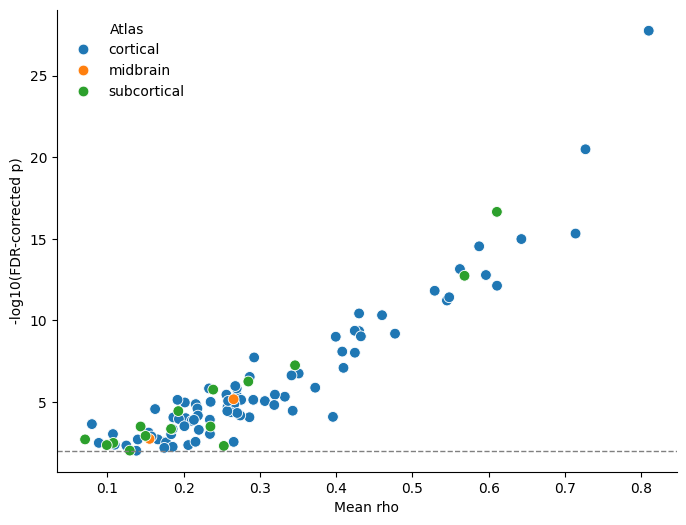

In [36]:
# plot significant rho values where axis are: rho value and fdr corrected p-value
# colored by the atlas

sig = model_summary.query("p_fdr < 0.01 and mean_rho > 0").copy()
sig["-log10 p_fdr"] = -np.log10(sig["p_fdr"])

colors = {"cortical": "tab:blue", "midbrain": "tab:orange", "subcortical": "tab:green"}

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=sig, x="mean_rho", y="-log10 p_fdr",
    hue="atlas", palette=colors, s=60, ax=ax,
)
ax.axhline(-np.log10(0.01), ls="--", c="grey", lw=1)   # FDR 0.01 threshold
ax.set_xlabel("Mean rho")
ax.set_ylabel("-log10(FDR-corrected p)")
ax.legend(title="Atlas", frameon=False)
sns.despine()
plt.show()

In [37]:
# NEGATIVE RHO
model_summary.query('p_fdr < 0.01').query("mean_rho < 0.0")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
41,cortical,Cuneal Cortex,Food cues vs. social and flower cues,32,-0.091583,-0.126845,-0.050972,5.237800e-05,4.155781e-04
47,cortical,Frontal Medial Cortex,Fasting vs. baseline and isolation,32,-0.088407,-0.129519,-0.046460,2.514644e-04,1.684811e-03
49,cortical,Frontal Medial Cortex,Food cues after fasting vs. all other conditions,32,-0.093060,-0.133259,-0.046223,2.985915e-04,1.936029e-03
50,cortical,Frontal Medial Cortex,Food cues vs. social and flower cues,32,-0.085901,-0.111470,-0.057653,1.007457e-06,1.239789e-05
51,cortical,Frontal Medial Cortex,Isolation vs. baseline and fasting,32,-0.070525,-0.107292,-0.032585,9.529815e-04,5.271999e-03
131,cortical,Intracalcarine Cortex,Food cues vs. social and flower cues,32,-0.104618,-0.146733,-0.059161,5.981932e-05,4.565956e-04
147,cortical,"Lateral Occipital Cortex, inferior division",Flower cues vs. social and food cues,32,-0.079049,-0.116818,-0.035597,7.722935e-04,4.423469e-03
148,cortical,"Lateral Occipital Cortex, inferior division",Food cues after fasting vs. all other conditions,32,-0.089643,-0.118184,-0.061102,1.241057e-06,1.439149e-05
165,cortical,Lingual Gyrus,Flower cues vs. social and food cues,32,-0.081890,-0.116317,-0.044784,1.395867e-04,9.787299e-04
210,cortical,Occipital Fusiform Gyrus,Flower cues vs. social and food cues,32,-0.090914,-0.128350,-0.050304,8.580668e-05,6.387830e-04


In [39]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').roi.value_counts()

roi
Occipital Fusiform Gyrus                          5
Cerebral White Matter                             4
Lingual Gyrus                                     4
Cerebral Cortex                                   4
Inferior Temporal Gyrus, temporooccipital part    3
Intracalcarine Cortex                             3
Supramarginal Gyrus, anterior division            3
Middle Temporal Gyrus, anterior division          3
Middle Frontal Gyrus                              3
Lateral Occipital Cortex, superior division       3
Occipital Pole                                    3
Temporal Occipital Fusiform Cortex                3
Inferior Frontal Gyrus, pars triangularis         3
Frontal Pole                                      3
Frontal Medial Cortex                             3
Cingulate Gyrus, posterior division               3
Superior Temporal Gyrus, anterior division        2
Superior Frontal Gyrus                            2
Angular Gyrus                                     2
Supramar

In [40]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').model.value_counts()

model
Social cues vs. food and flower cues                    41
Social cues after isolation vs. all other conditions    26
Isolation vs. baseline and fasting                       7
Deprivation-matched cues vs. all other conditions        6
Food cues vs. social and flower cues                     6
Baseline vs. fasting and isolation                       5
Flower cues vs. social and food cues                     4
Fasting vs. baseline and isolation                       4
Name: count, dtype: int64

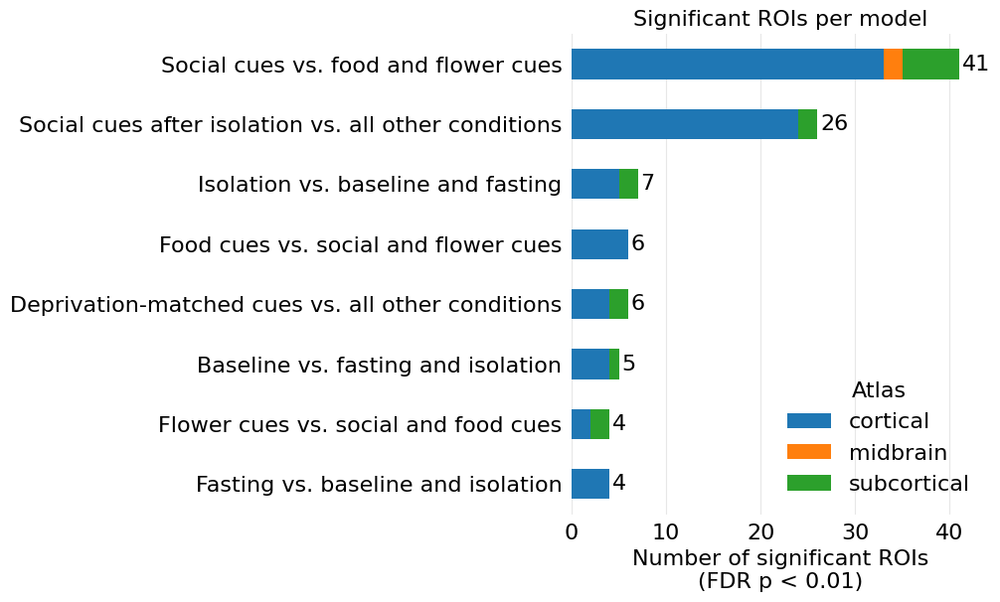

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

sig = model_summary.query("p_fdr < 0.01 and mean_rho > 0")

# 1) Number of significant ROIs per model (the value_counts from your screenshot)
# rows = model, columns = atlas, values = number of significant ROIs
counts = (
    sig.groupby(["model", "atlas"]).size().unstack(fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values().index]  # largest bar on top
colors = {"cortical": "tab:blue", "midbrain": "tab:orange", "subcortical": "tab:green"}

ax = counts.plot(
    kind="barh", stacked=True, figsize=(10, 6),
    color=[colors[a] for a in counts.columns],
)

for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 0.3, i, str(total), va="center")

ax.set_xlabel("Number of significant ROIs (FDR p < 0.01)")
ax.set_ylabel("")
ax.set_title("Significant ROIs per model")
ax.legend(title="atlas", frameon=False)

# remove the surrounding box
import seaborn as sns
sns.despine(left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# light vertical gridlines behind the bars, like the reference
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Readable, regular-weight text at the final printed size.
from textwrap import fill

labels = [str(model).replace("_", " ") for model in counts.index]
ax.set_yticks(range(len(counts)))
ax.set_yticklabels(labels, fontsize=16, fontweight="medium")

ax.tick_params(axis="x", labelsize=16, colors="black")
ax.set_xlabel("Number of significant ROIs\n(FDR p < 0.01)",
              fontsize=16, color="black", fontweight="medium")
ax.set_title("Significant ROIs per model", fontsize=16, fontweight="medium")
ax.legend(title="Atlas", frameon=False, fontsize=16, title_fontsize=16)
for text in ax.texts:
    text.set_fontsize(16)
    text.set_color("black")
    text.set_fontweight("medium")
ax.margins(x=0.08)

plt.tight_layout(pad=0.5)
# save as pdf
plt.savefig("signif_roi_atlases.pdf", bbox_inches="tight")   
plt.show()


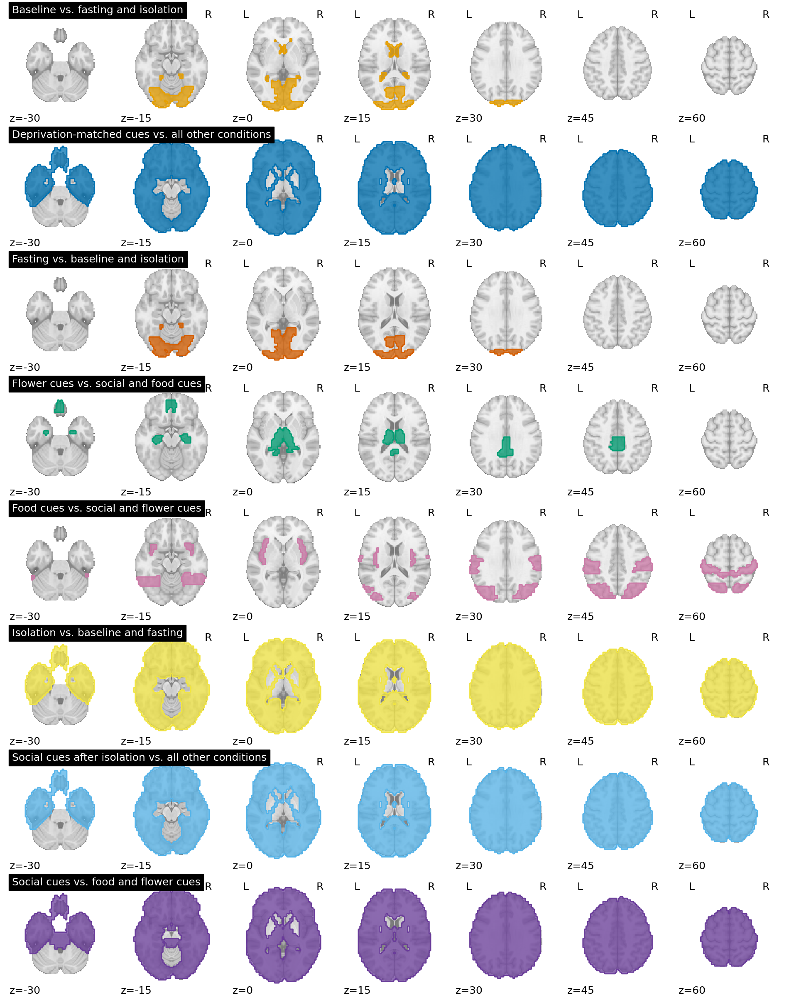

In [42]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import nibabel as nib
import numpy as np
from nilearn import plotting
from nilearn.image import resample_to_img


mask_dir = Path("../../masks_MNI152NLin2009cAsym")

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------


p_threshold = 0.01

# These coordinates are in millimeters and assume MNI space.
# Adjust them if your masks and anatomical background are
# in a different space.
slice_positions = [-30, -15, 0, 15, 30, 45, 60]

# Set to a matching anatomical NIfTI image if not using MNI.
# None uses Nilearn's default MNI template.
background_image = None

# ------------------------------------------------------------
# SELECT SIGNIFICANT RESULTS
# ------------------------------------------------------------

#significant = model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")
significant = (
    model_summary.loc[
        (model_summary["p_fdr"] < p_threshold) & (model_summary["mean_rho"] > 0),
        ["roi", "model"]
    ]
    .dropna()
    .drop_duplicates()
)

if significant.empty:
    raise ValueError("No significant ROI–model pairs found.")

models = sorted(significant["model"].unique())
rois = sorted(significant["roi"].unique())


# ------------------------------------------------------------
# FIND ROI MASKS
# ------------------------------------------------------------

def mask_name(path):
    if path.name.endswith(".nii.gz"):
        return path.name[:-7]
    if path.name.endswith(".nii"):
        return path.name[:-4]
    return None


mask_files = {}

for path in mask_dir.iterdir():
    name = mask_name(path)
    if name is not None:
        if name in mask_files:
            raise ValueError(f"Multiple masks found for: {name}")
        mask_files[name] = path

missing = [roi for roi in rois if roi not in mask_files]

if missing:
    raise FileNotFoundError(
        "Masks not found for:\n" + "\n".join(missing)
    )

# ------------------------------------------------------------
# LOAD MASKS ON A COMMON GRID
# ------------------------------------------------------------

#reference = nib.load(str(mask_files[rois[0]]))
from nilearn import datasets
reference = datasets.load_mni152_template()

if len(reference.shape) != 3:
    raise ValueError("Expected 3D ROI masks.")

roi_masks = {}

for roi in rois:
    mask = nib.load(str(mask_files[roi]))

    if len(mask.shape) != 3:
        raise ValueError(f"Mask for {roi} is not 3D.")

    if (
        mask.shape != reference.shape
        or not np.allclose(mask.affine, reference.affine)
    ):
        mask = resample_to_img(
            mask,
            reference,
            interpolation="nearest",
        )

    # Assumes binary masks with values 0 and 1.
    roi_masks[roi] = np.asarray(mask.dataobj) > 0.5


# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL
# ------------------------------------------------------------
# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL — MANUALLY POSITIONED
# ------------------------------------------------------------

from matplotlib.colors import ListedColormap

if len(models) > 20:
    raise ValueError("More than 20 models: choose a larger color palette.")

#colors = plt.get_cmap("tab20").colors
# Saturated, distinct colors (Okabe-Ito style + extras), up to 12 models
colors = [
    "#E69F00",  # orange
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#009E73",  # green
    "#CC79A7",  # pink
    "#F0E442",  # yellow
    "#56B4E9",  # sky blue
    "#6A3D9A",  # purple
    "#B15928",  # brown
    "#1B1B1B",  # near-black
    "#E31A1C",  # red
    "#33A02C",  # dark green
]
if len(models) > len(colors):
    raise ValueError("More models than colors; extend the list.")
n_models = len(models)

fig = plt.figure(figsize=(20, 3 * n_models))

# Leave a small gap between rows.
row_height = 1 / n_models
gap = 0.02 * row_height

for i, model in enumerate(models):
    color = colors[i]

    model_rois = significant.loc[
        significant["model"] == model, "roi"
    ].unique()

    combined = np.zeros(reference.shape, dtype=np.uint8)

    for roi in model_rois:
        combined[roi_masks[roi]] = 1

    if not combined.any():
        print(f"Warning: no mask voxels found for {model}")
        continue

    combined_img = nib.Nifti1Image(combined, reference.affine)

    # Place each row before Nilearn creates its slice axes.
    bottom = 1 - (i + 1) * row_height + gap
    ax = fig.add_axes([
        0.03,                  # left
        bottom,                # bottom
        0.94,                  # width
        row_height - 2 * gap,  # height
    ])

    plot_kwargs = {
        "display_mode": "z",
        "cut_coords": slice_positions,
        "figure": fig,
        "axes": ax,
        # "title": model.replace("_", " "),
        "draw_cross": False,
        "black_bg": False,
        "colorbar": False
    }
        # Omit anat_img for Nilearn's default MNI template.
    if background_image is not None:
        plot_kwargs["anat_img"] = background_image

    display = plotting.plot_anat(**plot_kwargs)

    display.add_overlay(
            combined_img,
            cmap=ListedColormap([color]),
            threshold=0.5,
            vmin=0,
            vmax=1,
            transparency=0.75,   # was 0.35
            interpolation="nearest",
        )
    display.title(model.replace("_", " "), size=18)   # bigger black-box title
    display.annotate(size=18)   

    display.add_contours(
        combined_img,
        levels=[0.5],
        colors=[color],
        linewidths=2.0,      # was 1.2
    )


plt.show()



In [43]:
# from pathlib import Path
# import textwrap

# import matplotlib.pyplot as plt
# from matplotlib.colors import ListedColormap
# import nibabel as nib
# import numpy as np
# from nilearn import plotting
# from nilearn.image import resample_to_img

# mask_dir = Path("../../masks_MNI152NLin2009cAsym")  

# # ------------------------------------------------------------
# # SETTINGS
# # ------------------------------------------------------------


# p_threshold = 0.01

# # These coordinates are in millimeters and assume MNI space.
# # Adjust them if your masks and anatomical background are
# # in a different space.
# slice_positions = [-30, -15, 0, 15, 30, 45, 60]

# # Set to a matching anatomical NIfTI image if not using MNI.
# # None uses Nilearn's default MNI template.
# background_image = None

# # ------------------------------------------------------------
# # SELECT SIGNIFICANT RESULTS
# # ------------------------------------------------------------

# #significant = model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")
# significant = (
#     model_summary.loc[
#         (model_summary["p_fdr"] < p_threshold) & (model_summary["mean_rho"] > 0),
#         ["roi", "model"]
#     ]
#     .dropna()
#     .drop_duplicates()
# )

# if significant.empty:
#     raise ValueError("No significant ROI–model pairs found.")

# #models = sorted(significant["model"].unique())
# models  = ['Social cues vs. food and flower cues', 
#            'Food cues vs. social and flower cues',
#            'Flower cues vs. social and food cues',
#            'Baseline vs. fasting and isolation',
#            'Isolation vs. baseline and fasting',
#            'Fasting vs. baseline and isolation',
#            'Social cues after isolation vs. all other conditions',
#            'Deprivation-matched cues vs. all other conditions']

# rois = sorted(significant["roi"].unique())

# # ------------------------------------------------------------
# # FIND ROI MASKS
# # ------------------------------------------------------------

# def mask_name(path):
#     if path.name.endswith(".nii.gz"):
#         return path.name[:-7]
#     if path.name.endswith(".nii"):
#         return path.name[:-4]
#     return None


# mask_files = {}

# for path in mask_dir.iterdir():
#     name = mask_name(path)
#     if name is not None:
#         if name in mask_files:
#             raise ValueError(f"Multiple masks found for: {name}")
#         mask_files[name] = path

# missing = [roi for roi in rois if roi not in mask_files]

# if missing:
#     raise FileNotFoundError(
#         "Masks not found for:\n" + "\n".join(missing)
#     )

# # ------------------------------------------------------------
# # LOAD MASKS ON A COMMON GRID
# # ------------------------------------------------------------

# #reference = nib.load(str(mask_files[rois[0]]))
# from nilearn import datasets
# reference = datasets.load_mni152_template()

# # Beta maps are MNI152NLin2009cAsym (fMRIPrep), same as Nilearn's template.
# # The Harvard-Oxford maxprob-thr0 masks are unthresholded and extend into CSF/skull,
# # so clip them to the brain for display.
# brain_mask = np.asarray(
#     resample_to_img(datasets.load_mni152_brain_mask(), reference, interpolation="nearest").dataobj
# ) > 0

# if len(reference.shape) != 3:
#     raise ValueError("Expected 3D ROI masks.")

# roi_masks = {}

# for roi in rois:
#     mask = nib.load(str(mask_files[roi]))

#     if len(mask.shape) != 3:
#         raise ValueError(f"Mask for {roi} is not 3D.")

#     if (
#         mask.shape != reference.shape
#         or not np.allclose(mask.affine, reference.affine)
#     ):
#         mask = resample_to_img(
#             mask,
#             reference,
#             interpolation="nearest",
#         )

#     # Assumes binary masks with values 0 and 1.
#     roi_masks[roi] = (np.asarray(mask.dataobj) > 0.5) & brain_mask

# # ------------------------------------------------------------
# # PLOT ONE ROW PER MODEL
# # ------------------------------------------------------------
# # ------------------------------------------------------------
# # PLOT ONE ROW PER MODEL — MANUALLY POSITIONED
# # ------------------------------------------------------------

# from matplotlib.colors import ListedColormap

# if len(models) > 20:
#     raise ValueError("More than 20 models: choose a larger color palette.")

# #colors = plt.get_cmap("tab20").colors
# # Saturated, distinct colors (Okabe-Ito style + extras), up to 12 models
# colors = [
#     "#E69F00",  # orange
#     "#0072B2",  # blue
#     "#D55E00",  # vermilion
#     "#009E73",  # green
#     "#CC79A7",  # pink
#     "#F0E442",  # yellow
#     "#56B4E9",  # sky blue
#     "#6A3D9A",  # purple
#     "#B15928",  # brown
#     "#1B1B1B",  # near-black
#     "#E31A1C",  # red
#     "#33A02C",  # dark green
# ]
# if len(models) > len(colors):
#     raise ValueError("More models than colors; extend the list.")
# n_models = len(models)

# fig = plt.figure(figsize=(20, 3 * (n_models-1)))

# # Leave a small gap between rows.
# row_height = 1 / n_models
# gap = 0.02 * row_height

# for i, model in enumerate(models):
#     color = colors[i]

#     model_rois = significant.loc[
#         significant["model"] == model, "roi"
#     ].unique()

#     combined = np.zeros(reference.shape, dtype=np.uint8)

#     for roi in model_rois:
#         combined[roi_masks[roi]] = 1

#     if not combined.any():
#         print(f"Warning: no mask voxels found for {model}")
#         continue

#     combined_img = nib.Nifti1Image(combined, reference.affine)

#     # Place each row before Nilearn creates its slice axes.
#     bottom = 1 - (i + 1) * row_height + gap
#     ax = fig.add_axes([
#         0.03,                  # left
#         bottom,                # bottom
#         0.94,                  # width
#         row_height - 2 * gap,  # height
#     ])

#     plot_kwargs = {
#         "display_mode": "z",
#         "cut_coords": slice_positions,
#         "figure": fig,
#         "axes": ax,
#         # "title": model.replace("_", " "),
#         "draw_cross": False,
#         "black_bg": False,
#         "colorbar": False
#     }

#     # Omit anat_img for Nilearn's default MNI template.
#     if background_image is not None:
#         plot_kwargs["anat_img"] = background_image

#     display = plotting.plot_anat(**plot_kwargs)

#     display.add_overlay(
#             combined_img,
#             cmap=ListedColormap([color]),
#             threshold=0.5,
#             vmin=0,
#             vmax=1,
#             transparency=0.75,   # was 0.35
#             interpolation="nearest",
#         )
#     display.title(model.replace("_", " "), size=18)   # bigger black-box title
#     # L/R labels only on the last row, so they don't collide with the titles
#     display.annotate(size=18, left_right=(i == n_models - 1))

#     display.add_contours(
#         combined_img,
#         levels=[0.5],
#         colors=[color],
#         linewidths=2.0,      # was 1.2
#     )

# plt.savefig("rdms_roi_brain.pdf", bbox_inches="tight")
# plt.show()


In [44]:
# def plot_group_average(roi_name):
#     mats = rdms["rdms"][:, list(rdms["rois"]).index(roi_name)]
#     if mats.size == 0:
#         print(f"No subjects available for {roi_name}")
#         return

#     stacked = np.stack(mats, axis=0)
#     mean_rdm = np.mean(stacked, axis=0)  # Across-subject mean
#     n_subjects = stacked.shape[0]
#     sample_sd = np.std(stacked, axis=0, ddof=1)
#     sem_rdm = sample_sd / np.sqrt(n_subjects)

#     labels = [
#         "food_baseline", "social_baseline", "flowers_baseline",
#         "food_fasting", "social_fasting", "flowers_fasting",
#         "food_isolation", "social_isolation", "flowers_isolation",
#     ]

#     fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)

#     for ax, matrix, title, colorbar_label in [
#         (axes[0], mean_rdm, f"Group mean | {roi_name}", "Mean crossnobis distance"),
#         #(axes[1], std_rdm, f"Standard deviation | {roi_name}", "SD of crossnobis distance"),
#         (axes[1], sem_rdm, f"Standard error of the mean | {roi_name}", "SEM of crossnobis distance"),
#     ]:
#         image = ax.imshow(matrix, cmap="viridis", interpolation="nearest")
#         ax.set_title(title)
#         ax.set_xticks(range(len(labels)), labels=labels, rotation=90)
#         ax.set_yticks(range(len(labels)), labels=labels)

#         for row in range(matrix.shape[0]):
#             for col in range(matrix.shape[1]):
#                 value = matrix[row, col]
#                 rgba = image.cmap(image.norm(value))
#                 brightness = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
#                 ax.text(
#                     col, row, f"{value:.3f}",
#                     ha="center", va="center",
#                     color="black" if brightness > 0.55 else "white",
#                     fontsize=7,
#                 )

#         fig.colorbar(image, ax=ax, label=colorbar_label)

#     plt.show()
    

# for roi_name in list(rdms["rois"]):
#     plot_group_average(roi_name)

food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting


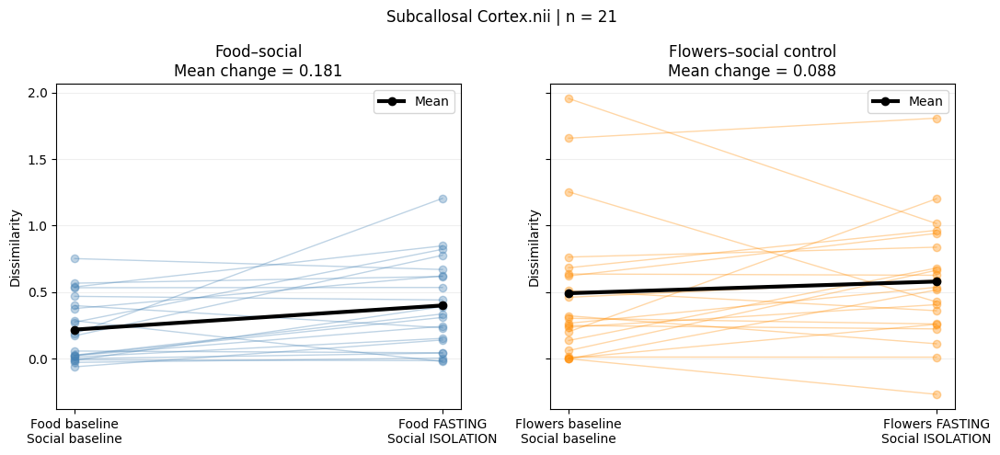

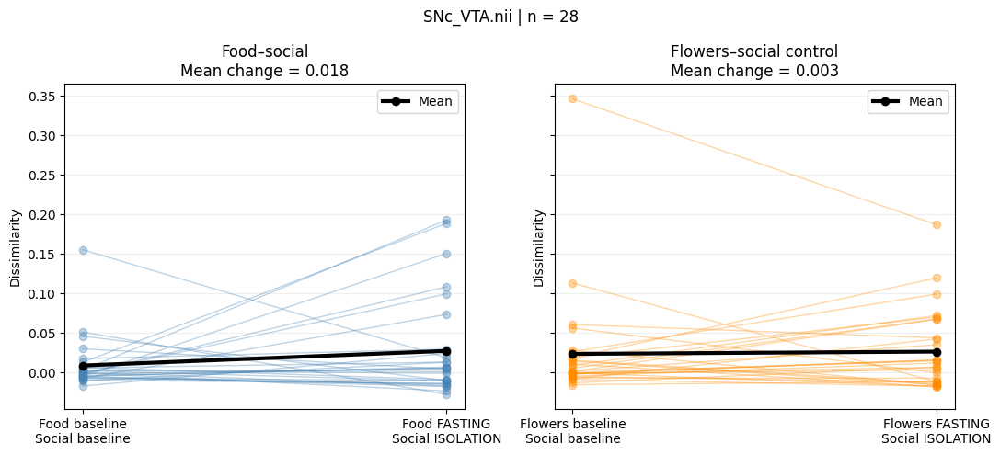

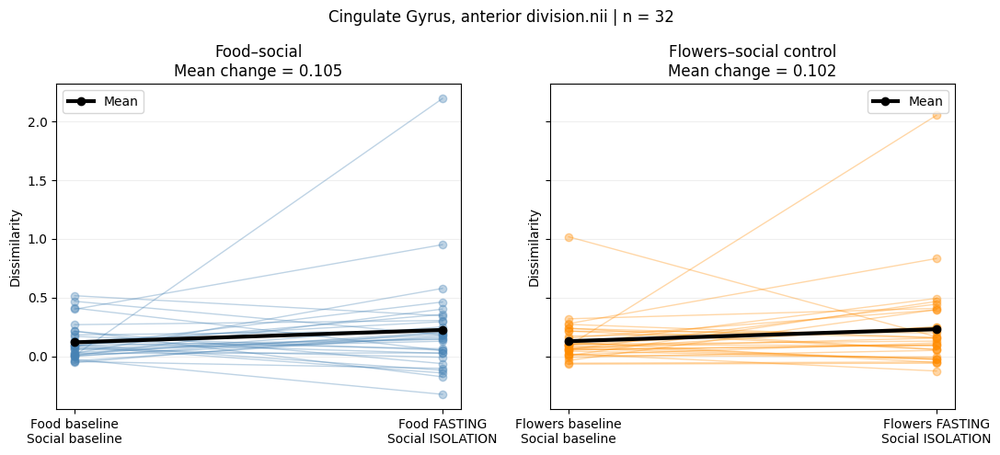

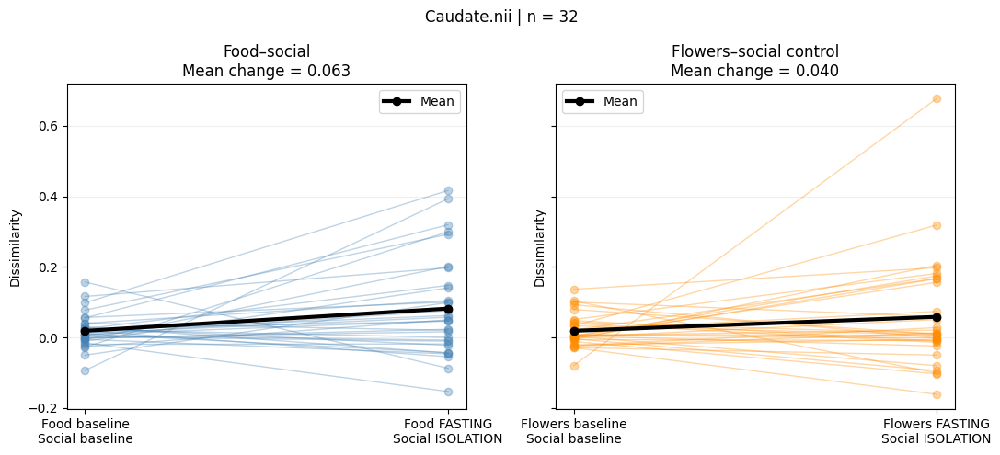

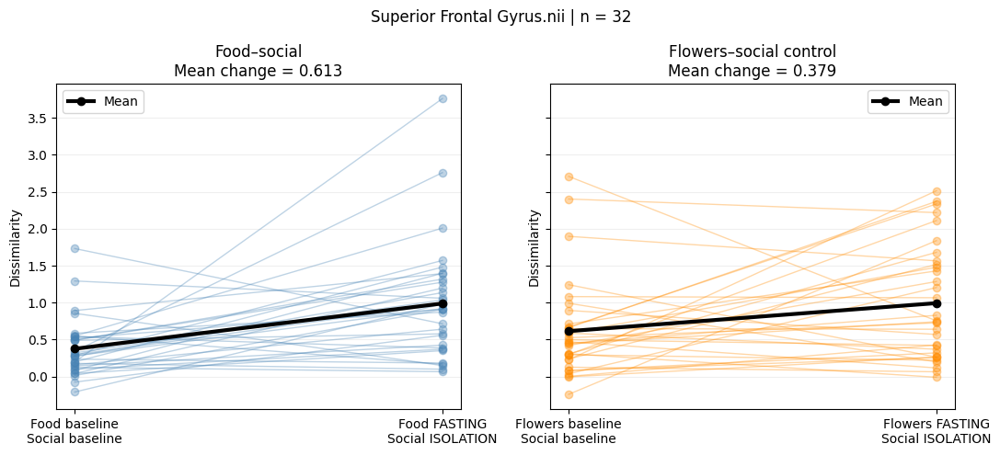

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping HN.nii: insufficient complete pairs.


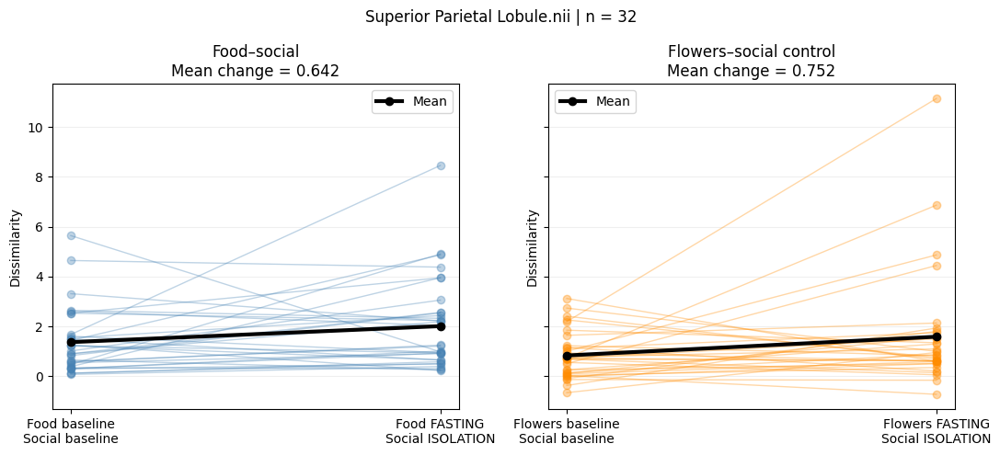

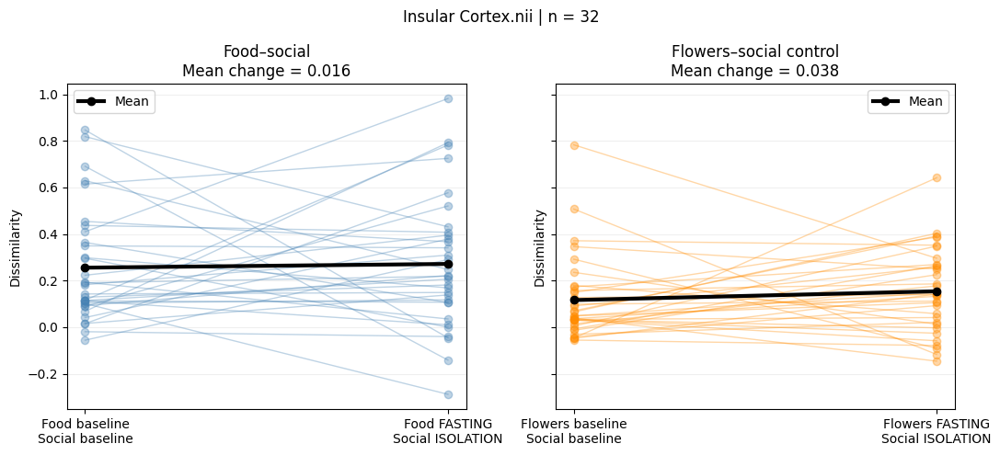

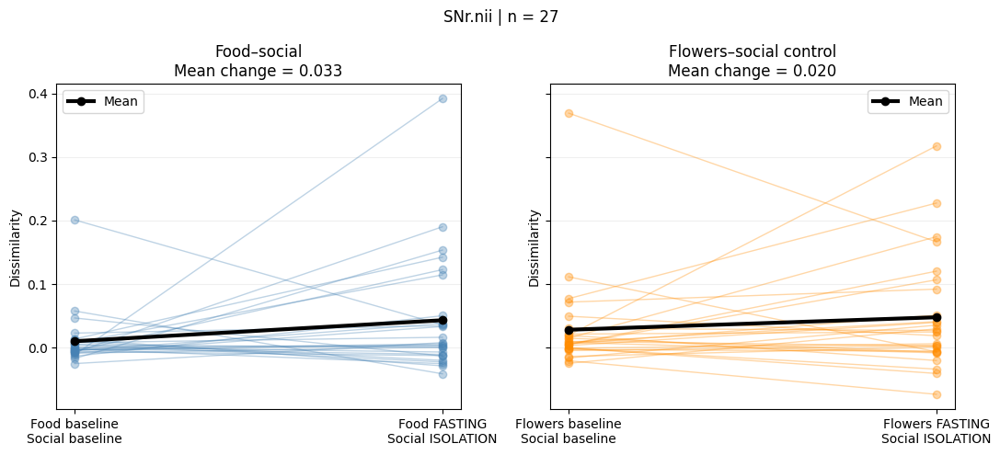

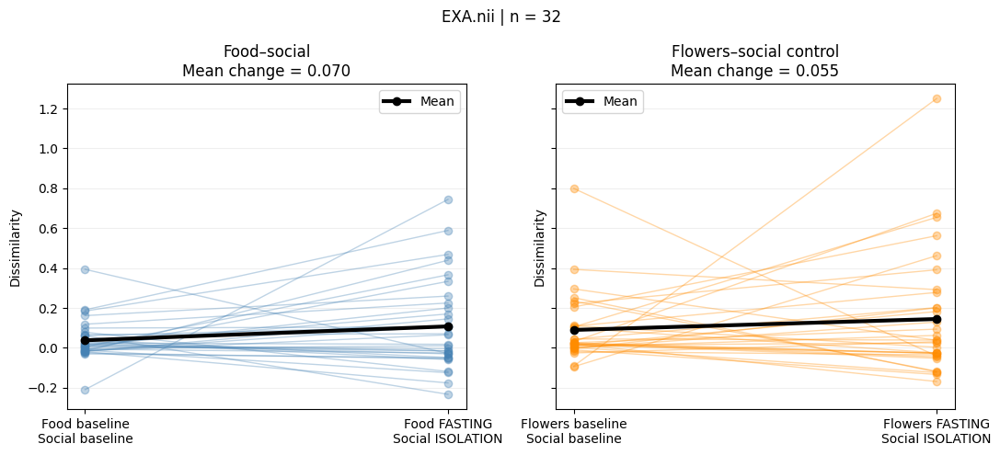

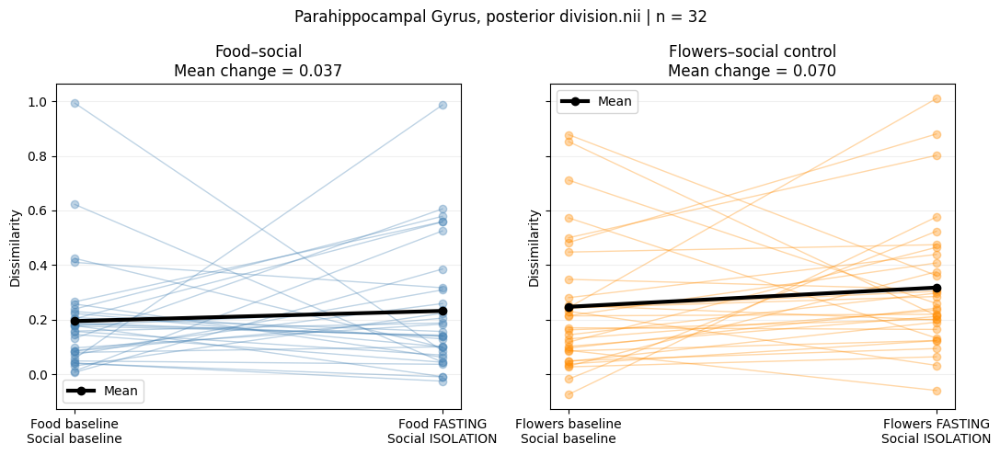

...

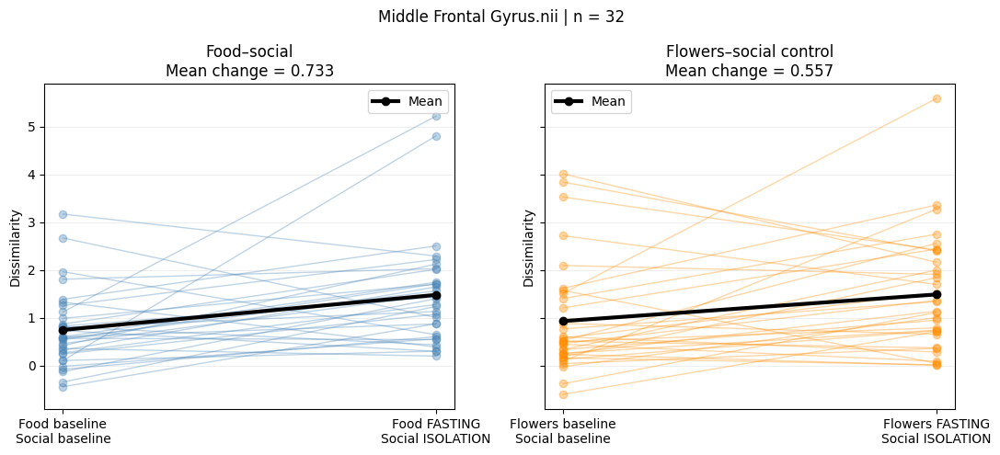

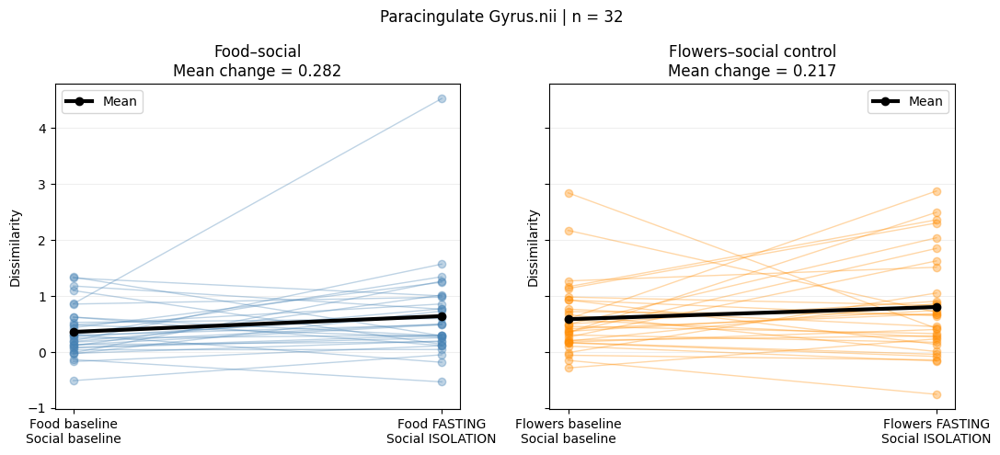

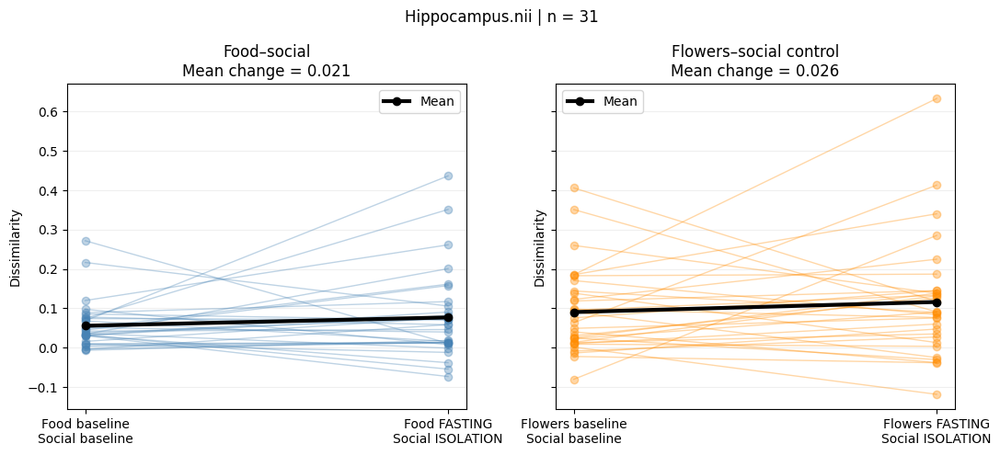

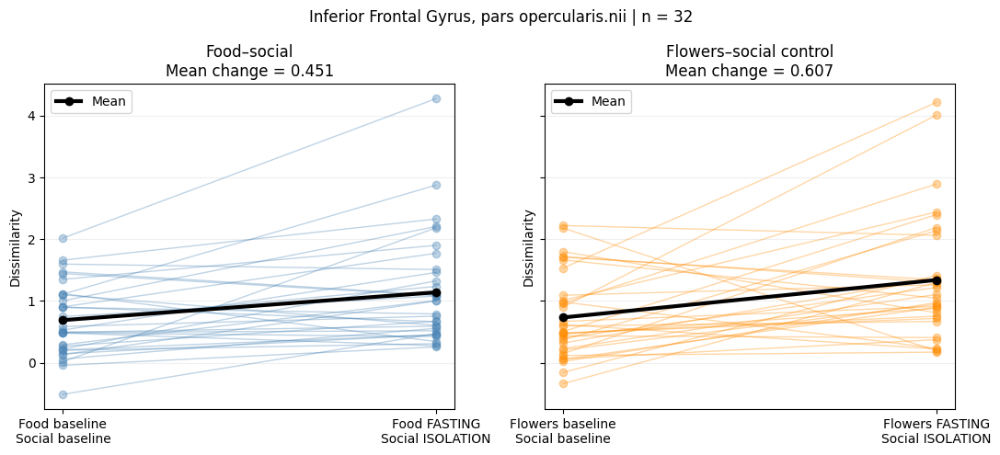

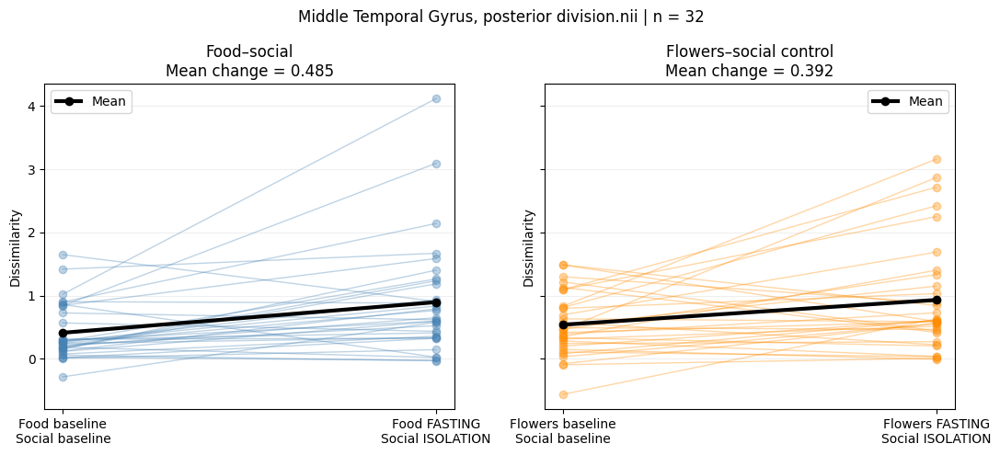

Skipping Inferior Temporal Gyrus, anterior division.nii: insufficient complete pairs.


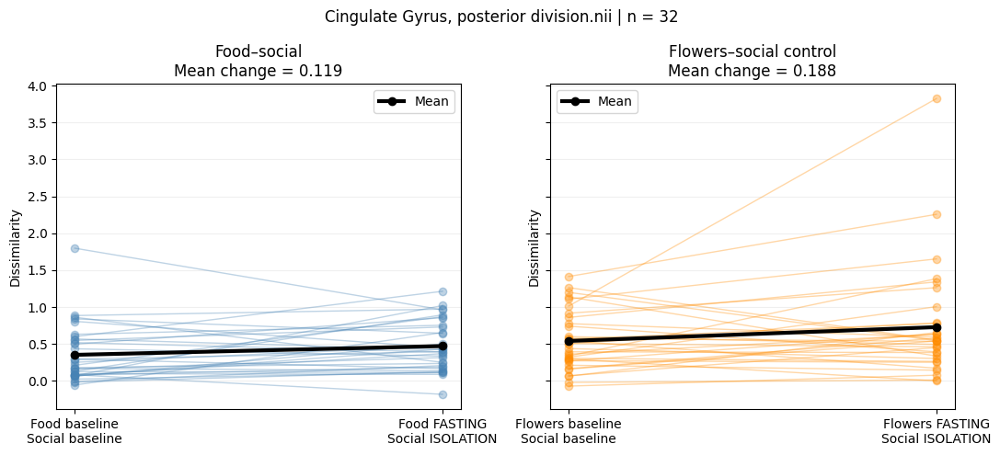

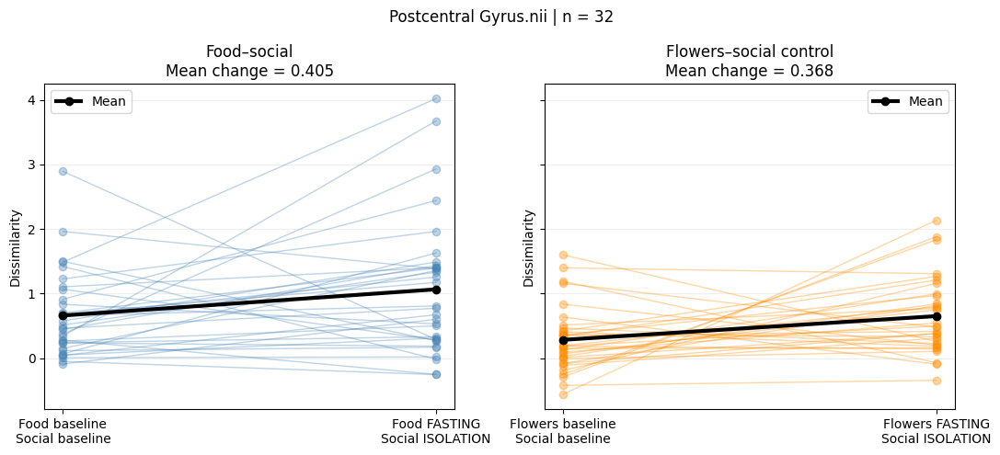

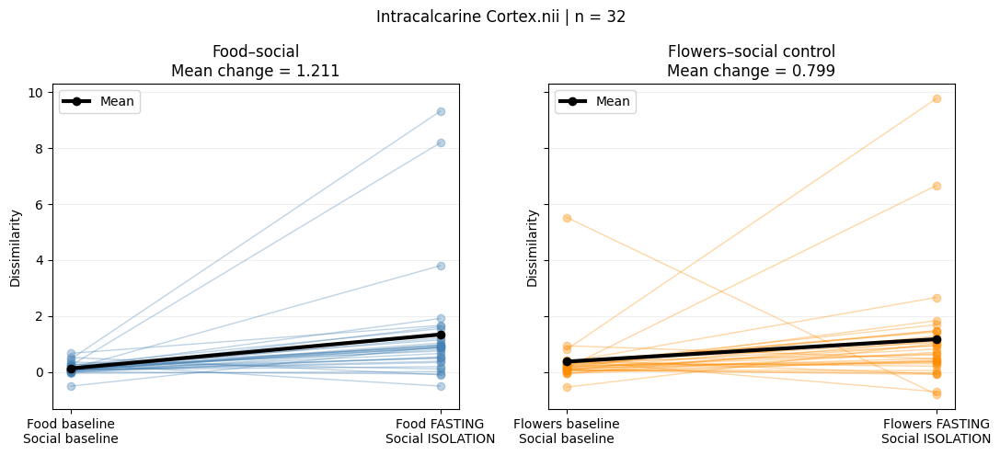

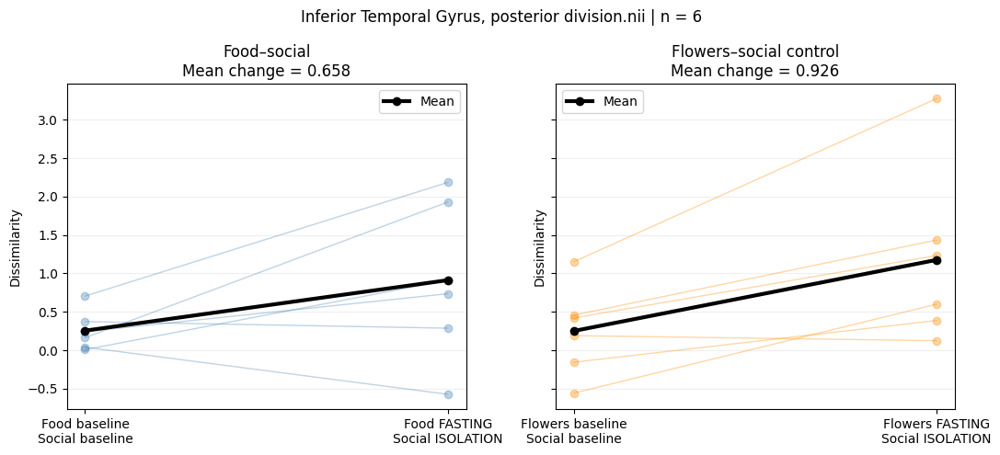

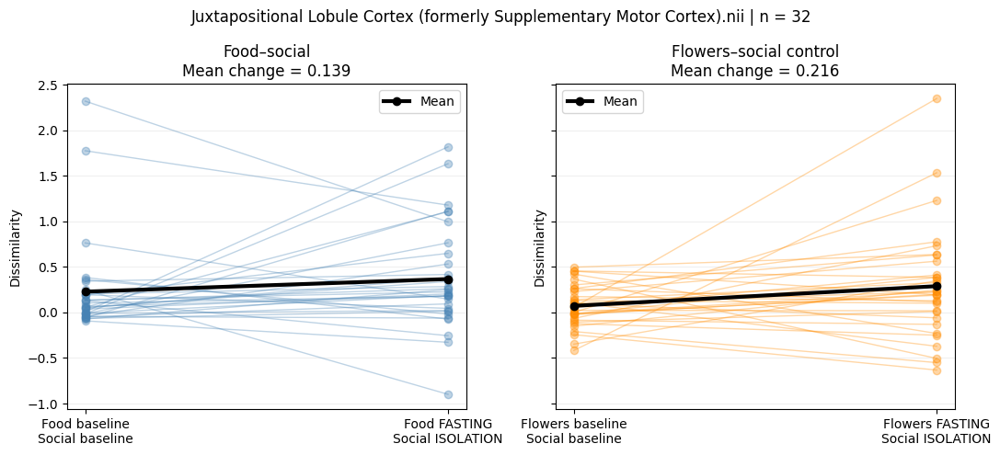

...

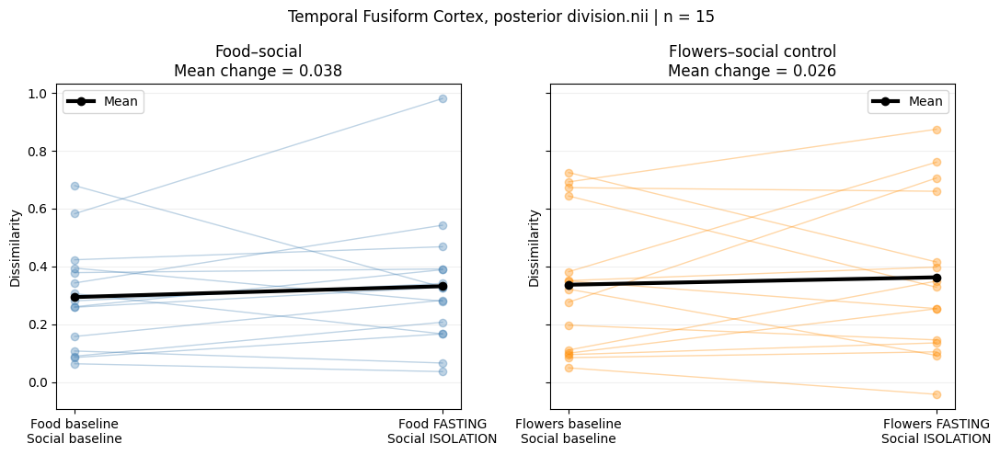

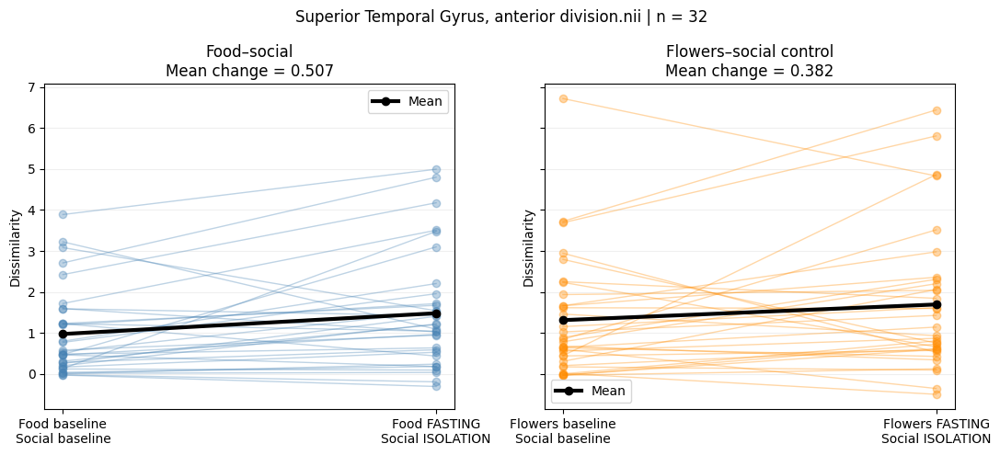

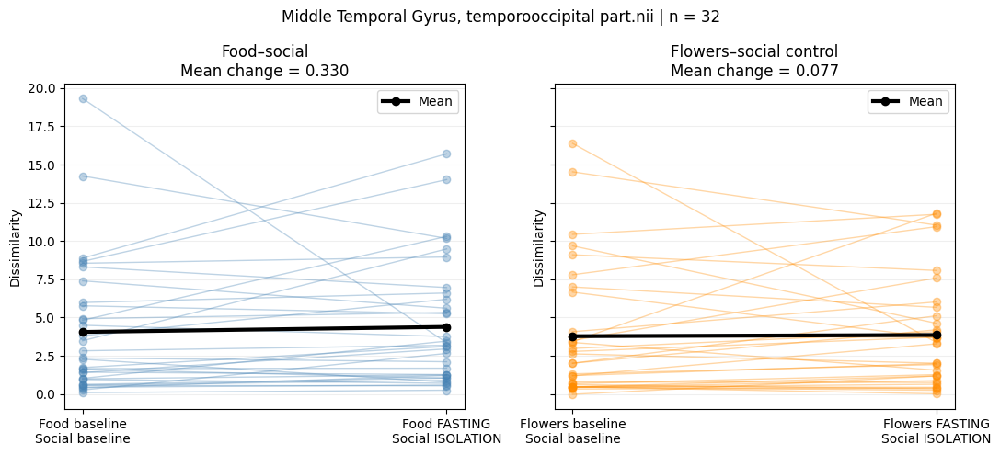

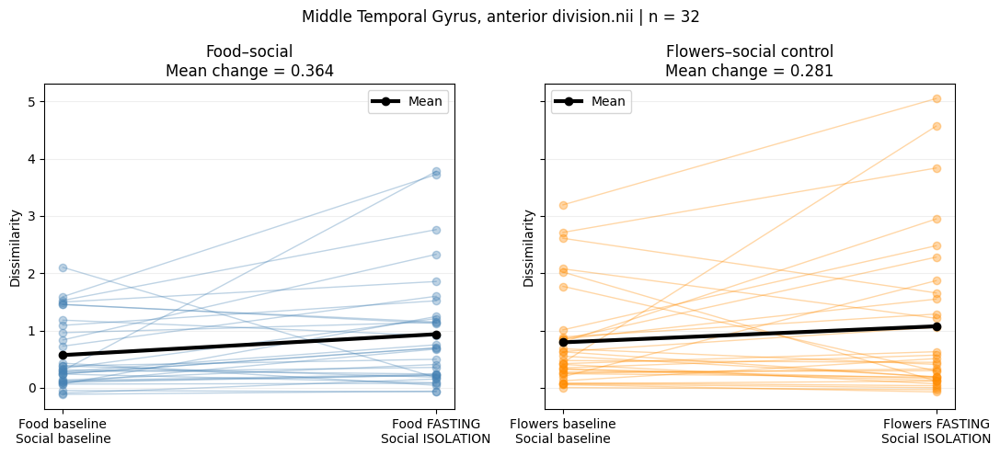

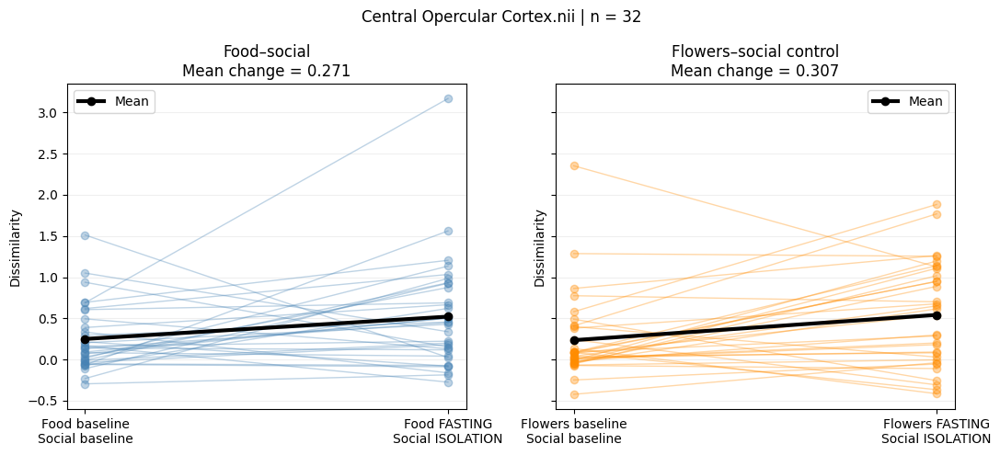

                                                                    ROI  n  food_change  control_change  difference_in_changes    p_food  p_change_difference  p_food_fdr  p_change_difference_fdr
                                                 Subcallosal Cortex.nii 21       0.1811         0.08758                0.09356   0.01078               0.3834     0.04027                   0.8715
                                                            SNc_VTA.nii 28      0.01847        0.002914                0.01556    0.1914               0.3442      0.2726                   0.8715
                                 Cingulate Gyrus, anterior division.nii 32       0.1052          0.1018               0.003376    0.1996               0.9409      0.2726                   0.9682
                                                            Caudate.nii 32       0.0632         0.03954                0.02366   0.02043               0.3018     0.06594                   0.8715
                         

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[food_base, social_base],
            rdm[food_fast, social_iso],       # Cross-condition target
            rdm[flowers_base, social_base],
            rdm[flowers_fast, social_iso],    # Cross-condition control
        ])

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    food_baseline, food_matched, control_baseline, control_matched = values.T

    food_change = food_matched - food_baseline
    control_change = control_matched - control_baseline

    # Does the food–social change differ from the flowers–social change?
    interaction = ttest_rel(food_change, control_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "food_change": food_change.mean(),
        "control_change": control_change.mean(),
        "difference_in_changes": (food_change - control_change).mean(),
        "p_food": ttest_rel(food_matched, food_baseline).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    panels = [
        (
            food_baseline, food_matched, "Food–social",
            ["Food baseline\nSocial baseline",
             "Food FASTING\nSocial ISOLATION"],
            "steelblue",
        ),
        (
            control_baseline, control_matched, "Flowers–social control",
            ["Flowers baseline\nSocial baseline",
             "Flowers FASTING\nSocial ISOLATION"],
            "darkorange",
        ),
    ]

    for ax, (baseline, matched, title, labels, color) in zip(axes, panels):
        for b, m in zip(baseline, matched):
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.35, linewidth=1,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean",
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_food", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

In [46]:
participant_scores

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.294134,42,17,40,47
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.155089,42,17,40,47
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,0.304830,42,17,40,47
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.518746,42,17,40,47
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,-0.251351,42,17,40,47
...,...,...,...,...,...,...,...,...,...
18877,cortical,sub-SAXSISO42,Central Opercular Cortex,Isolation vs. baseline and fasting,0.743358,43,6,41,50
18878,cortical,sub-SAXSISO42,Central Opercular Cortex,Fasting vs. baseline and isolation,-0.208568,43,6,41,50
18879,cortical,sub-SAXSISO42,Central Opercular Cortex,Social cues after isolation vs. all other cond...,0.430930,43,6,41,50
18880,cortical,sub-SAXSISO42,Central Opercular Cortex,Food cues after fasting vs. all other conditions,-0.450225,43,6,41,50


food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting
flowers, isolation: flowers_isolation


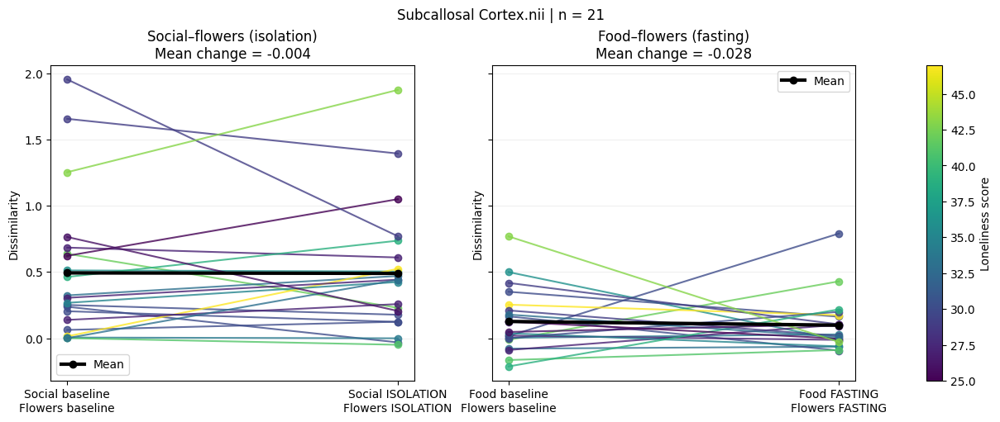

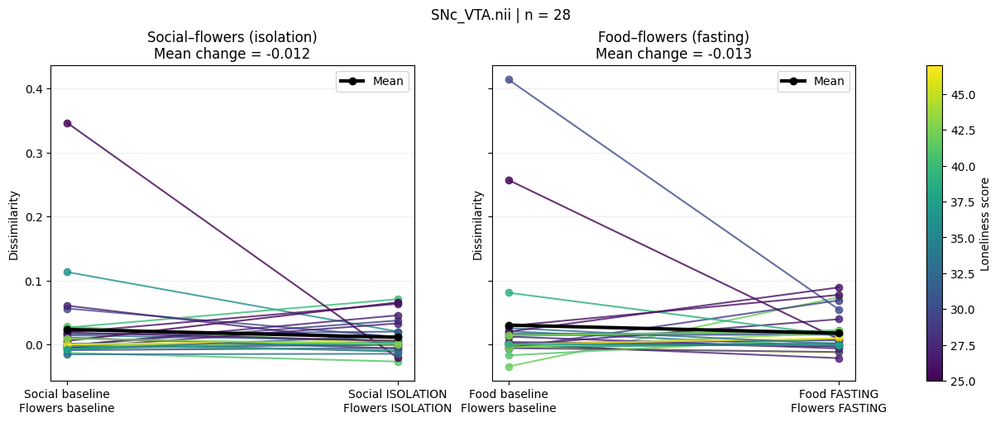

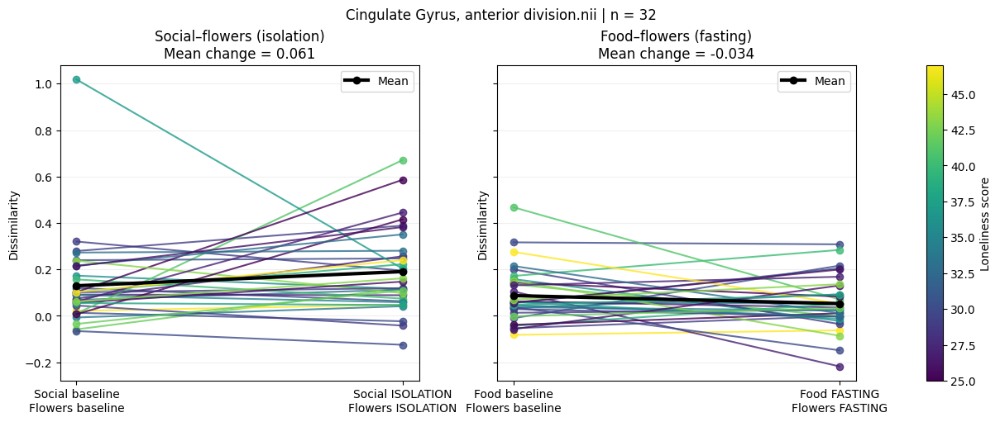

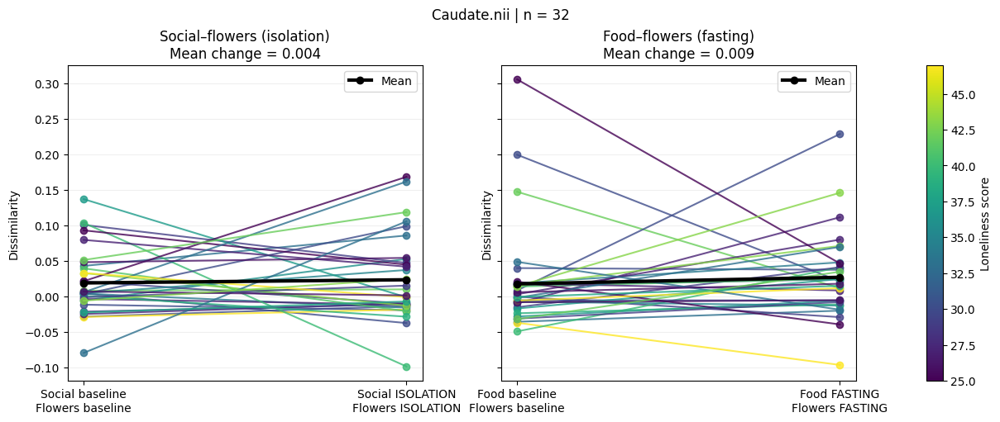

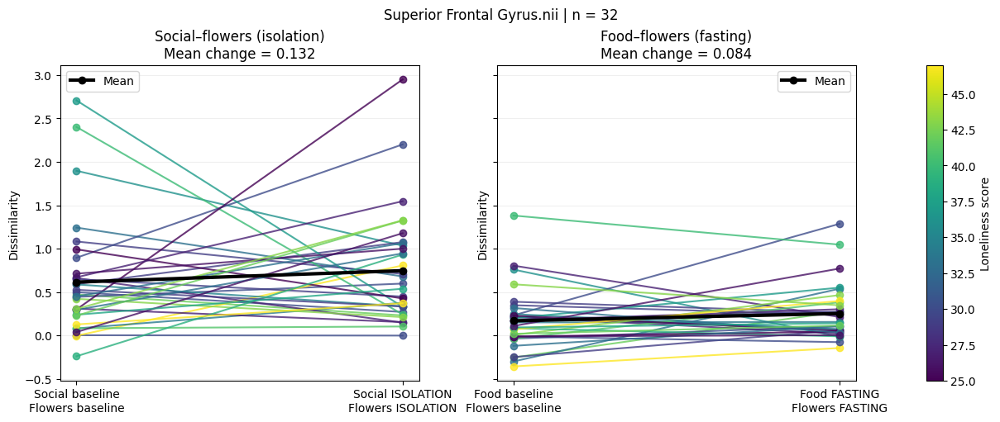

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping HN.nii: insufficient complete pairs.


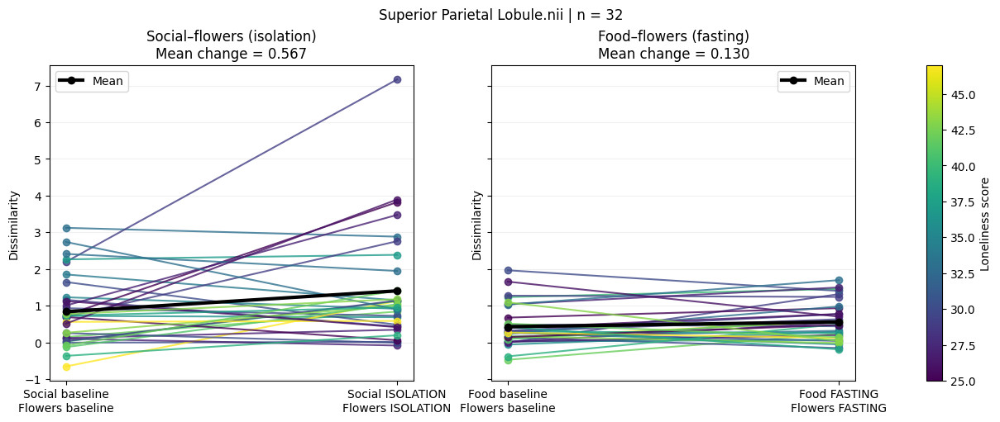

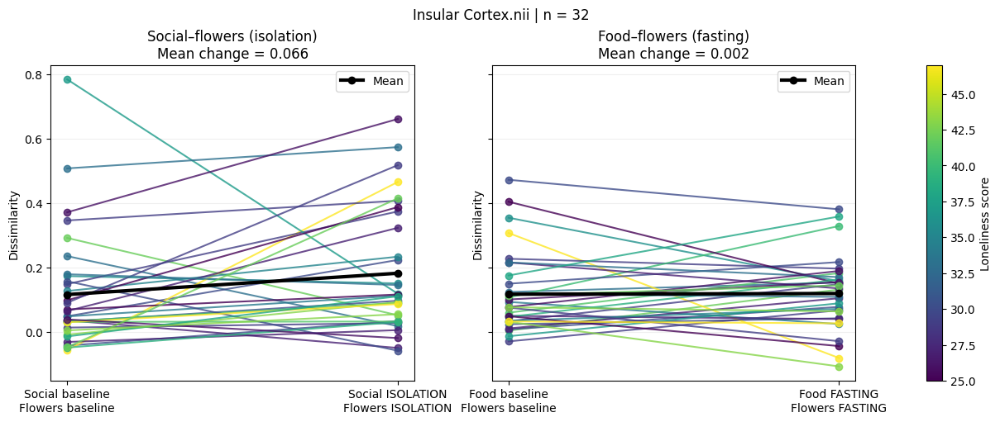

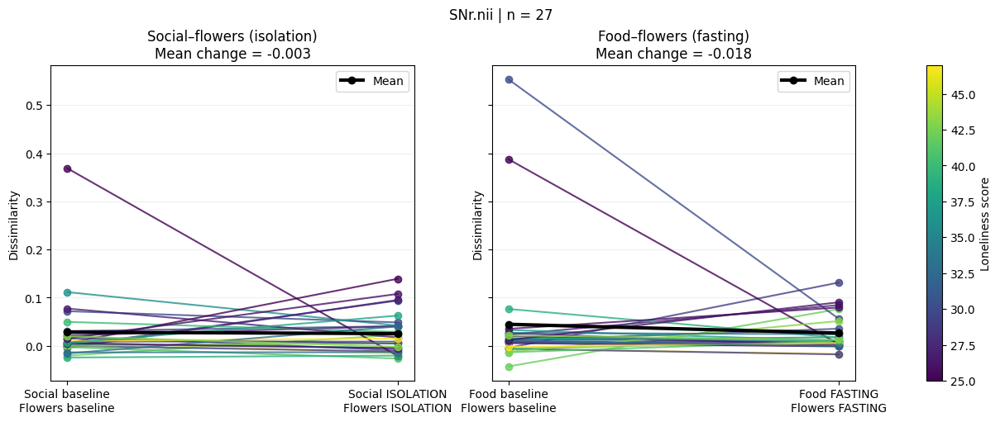

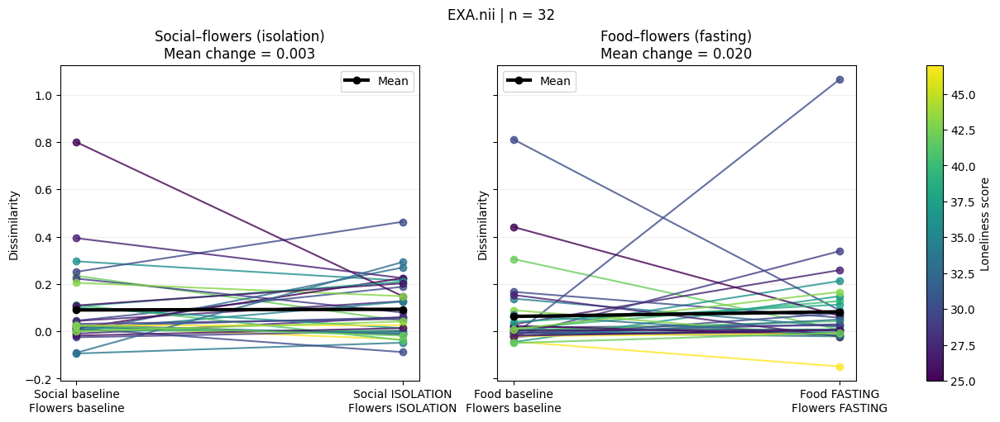

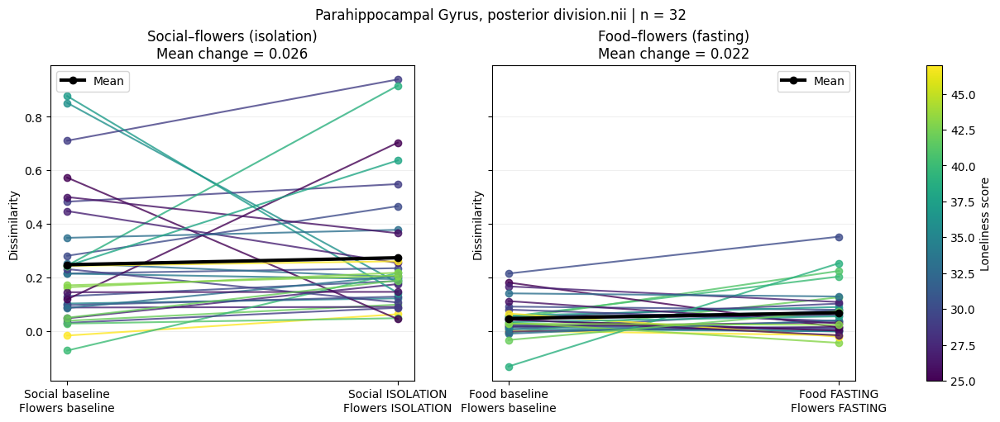

...

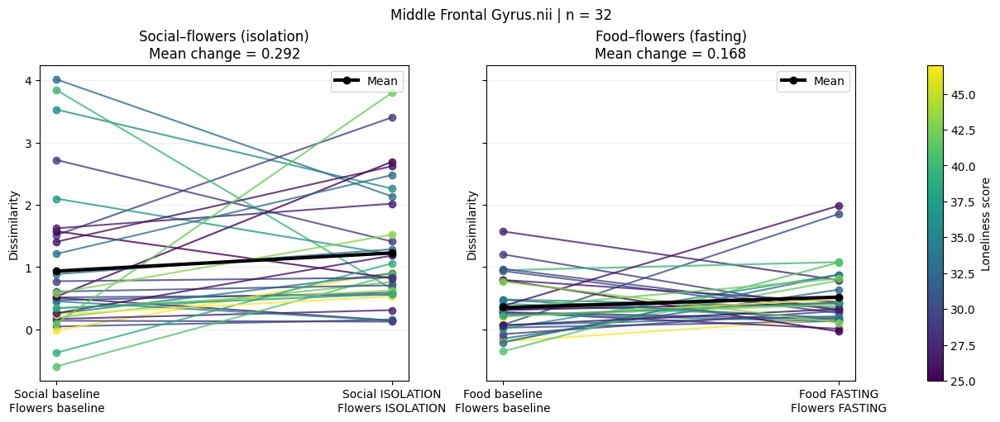

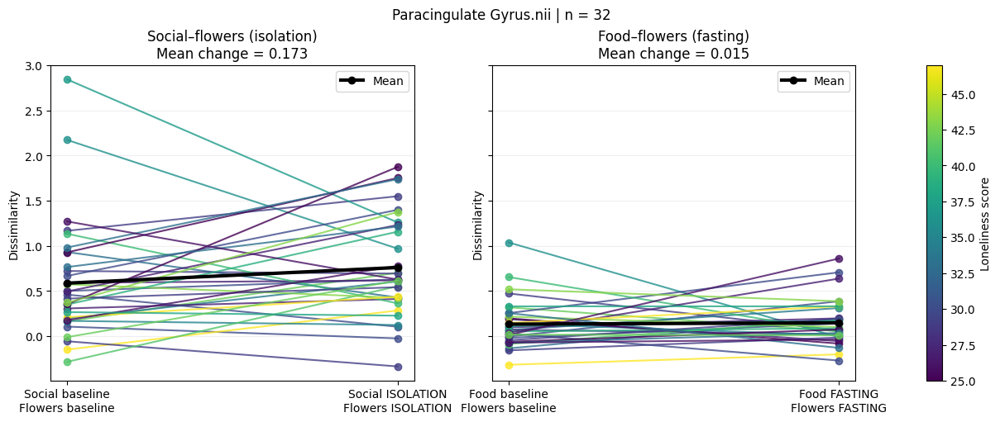

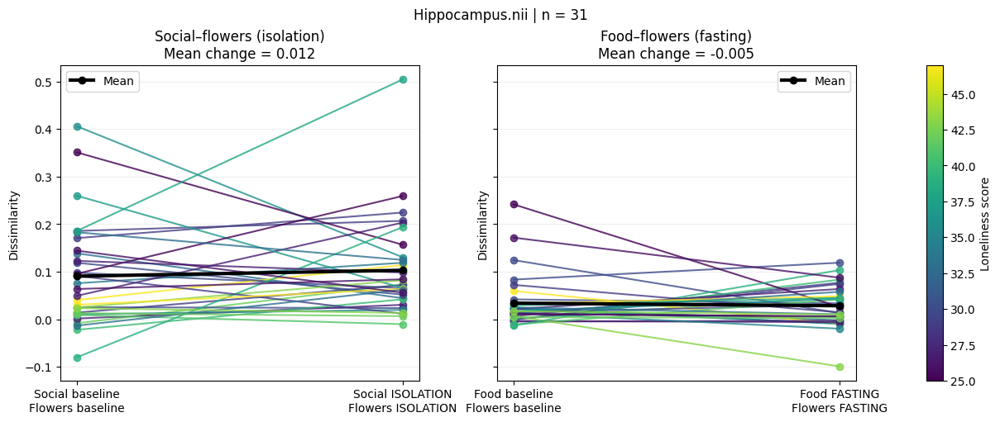

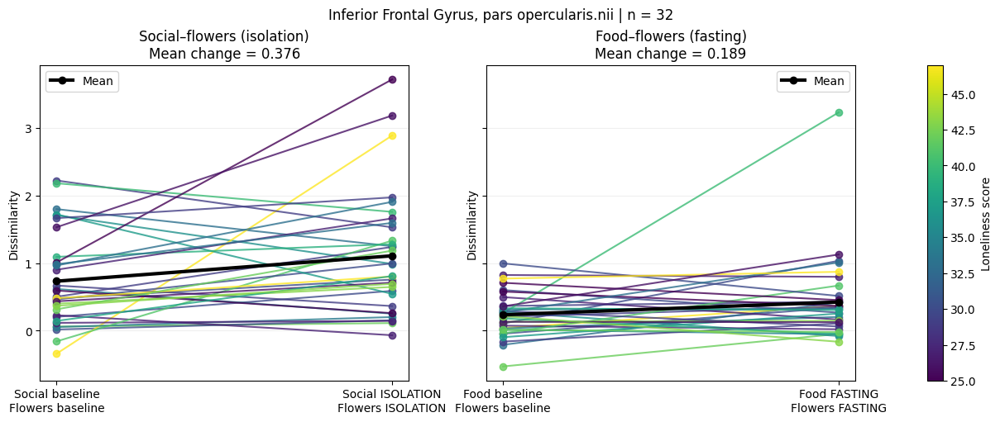

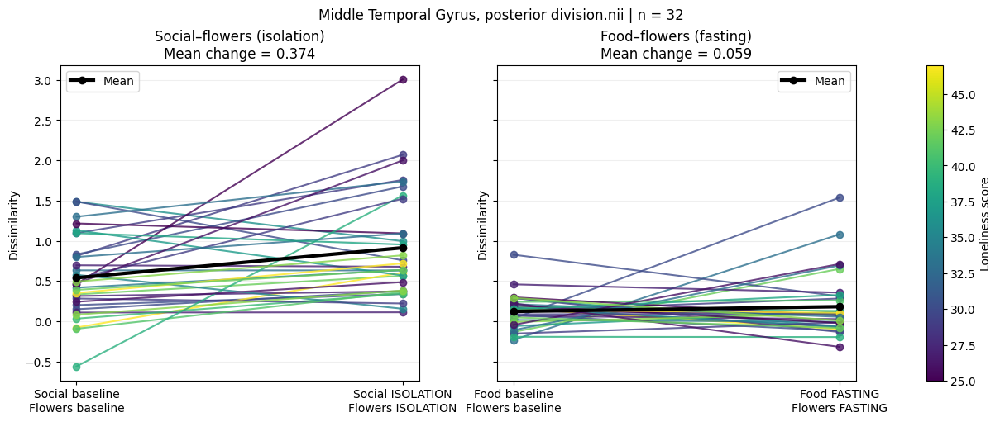

Skipping Inferior Temporal Gyrus, anterior division.nii: insufficient complete pairs.


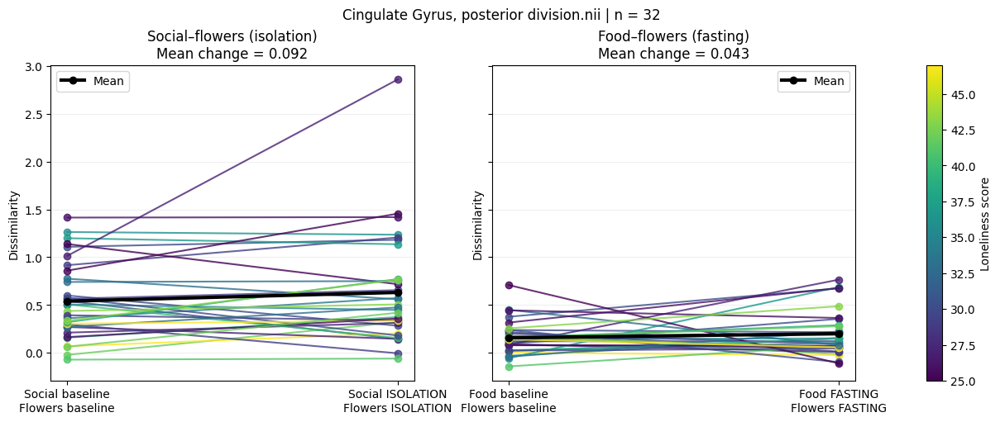

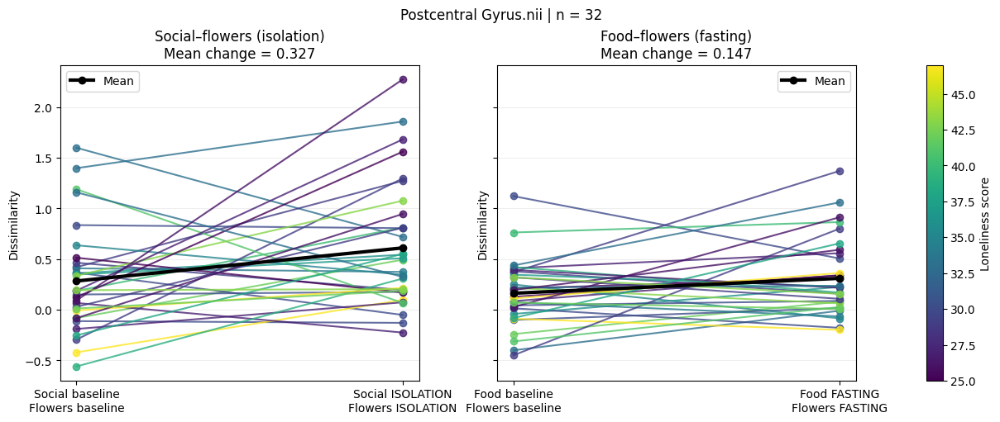

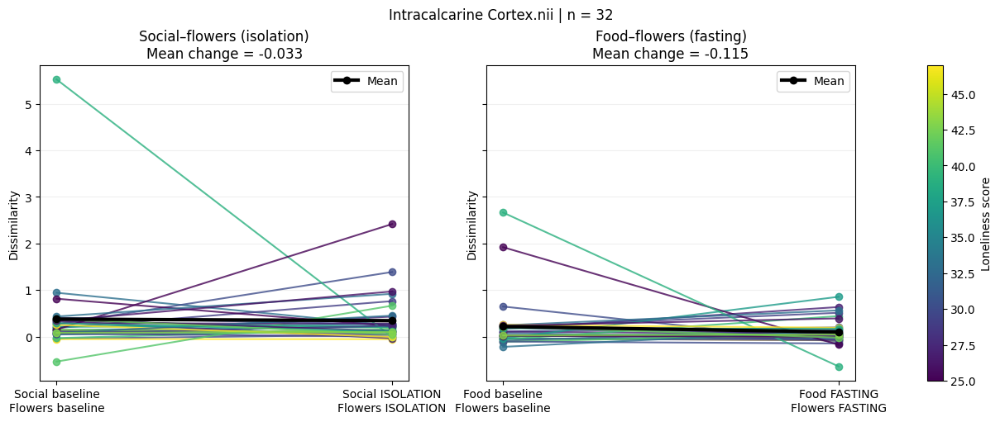

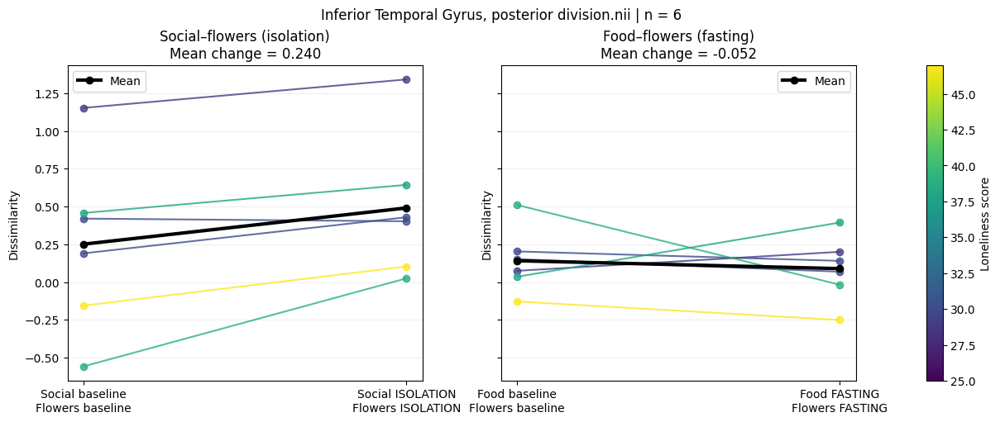

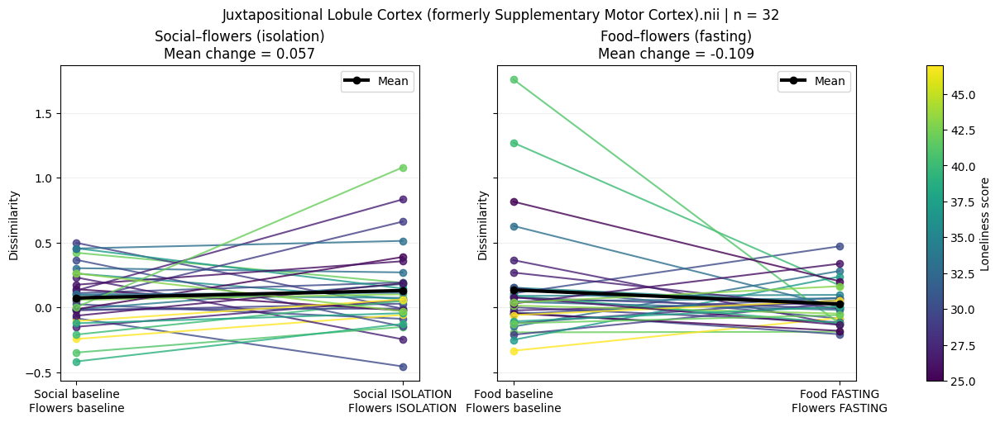

...

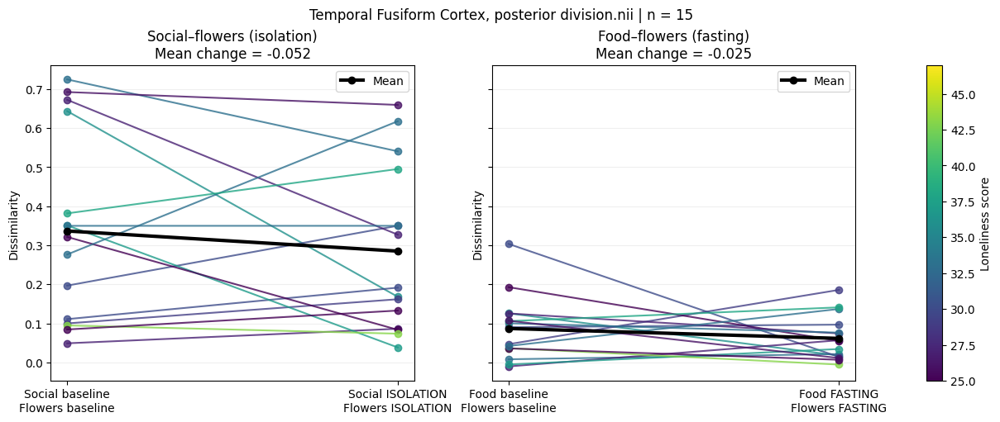

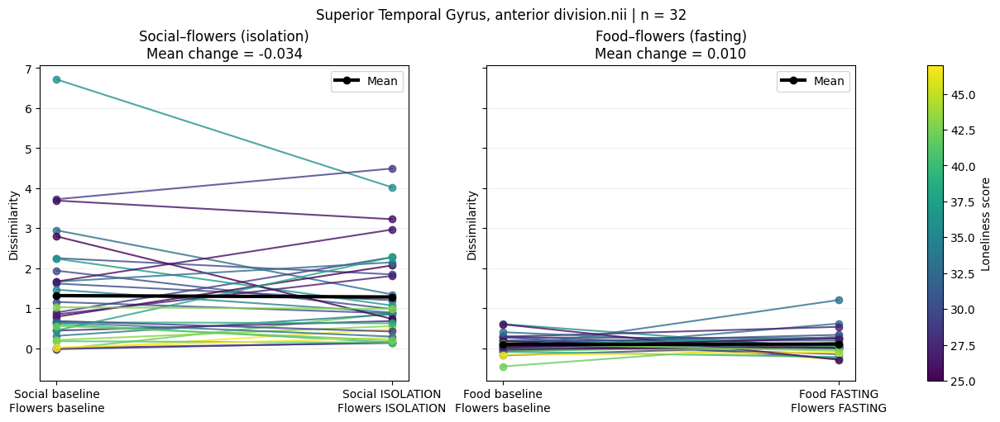

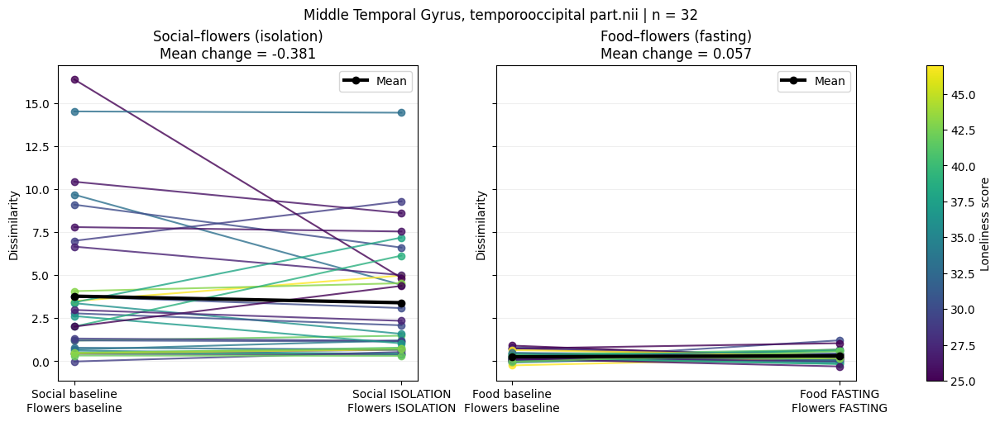

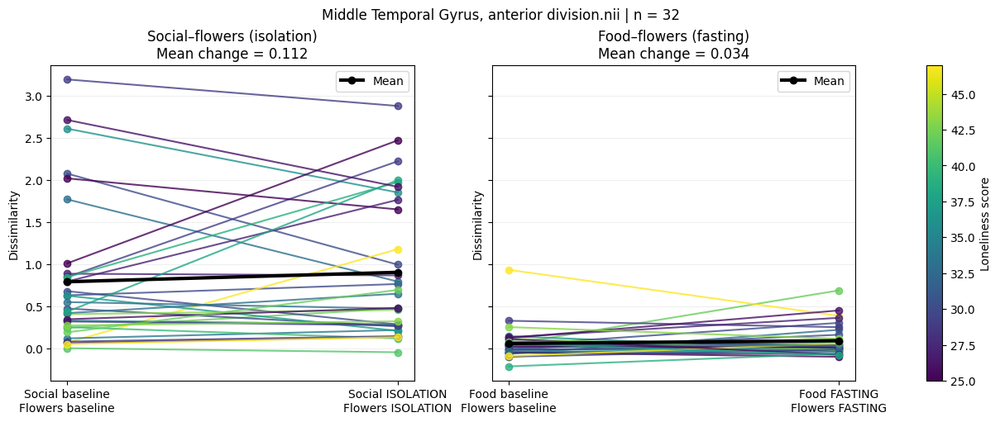

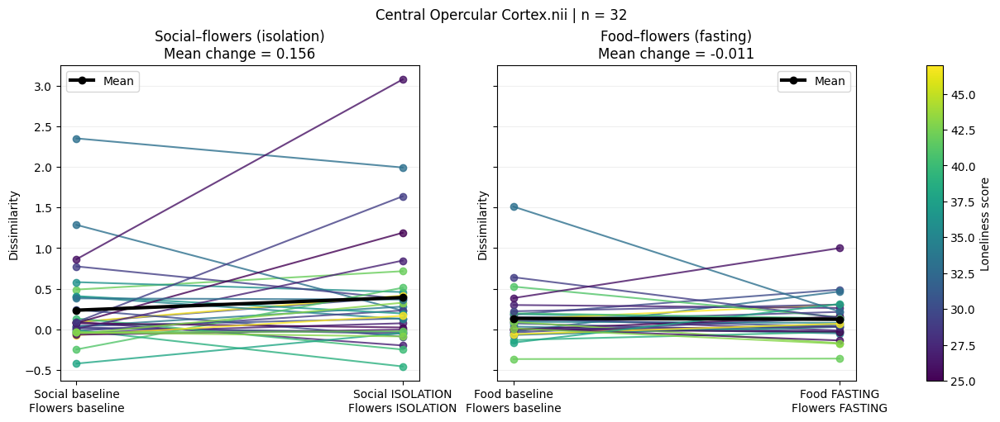

                                                                    ROI  n  isolation_change  fasting_change  difference_in_changes  p_isolation  p_fasting  p_change_difference  p_isolation_fdr  p_fasting_fdr  p_change_difference_fdr
                                                 Subcallosal Cortex.nii 21         -0.003758        -0.02807                0.02432       0.9662     0.7054               0.8424           0.9662         0.9107                   0.9613
                                                            SNc_VTA.nii 28          -0.01225         -0.0126              0.0003536       0.4074     0.4673               0.9816           0.7471         0.8927                   0.9954
                                 Cingulate Gyrus, anterior division.nii 32            0.0611        -0.03439                0.09549       0.1607     0.2035              0.08338           0.5037         0.8927                   0.8918
                                                            Caud

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests


# social_baseline and control_baseline VS social_isolation and control_isolation
# food_baseline and control_baseline VS food_fasting and control_fasting

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")
flowers_iso = find_condition("flowers", "isolation")

# Loneliness score per participant, used to color the lines
loneliness_by_subject = (
    behavioral_df.set_index("subject")["Loneliness_Score"]
    .astype(float)
    .reindex([str(s) for s in rdms["subjects"]])
)
loneliness_cmap = plt.cm.viridis
loneliness_norm = plt.Normalize(
    loneliness_by_subject.min(), loneliness_by_subject.max()
)

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[social_base, flowers_base],
            rdm[social_iso, flowers_iso],       
            rdm[food_base, flowers_base],
            rdm[food_fast, flowers_fast],    
        ])

    values = np.asarray(values, dtype=float)
    complete = np.isfinite(values).all(axis=1)
    values = values[complete]
    loneliness = loneliness_by_subject.to_numpy()[complete]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    social_base_pair, social_iso_pair, food_base_pair, food_fast_pair = values.T

    isolation_change = social_iso_pair - social_base_pair
    fasting_change = food_fast_pair - food_base_pair

    # Does the isolation change (social–flowers) differ from the fasting change (food–flowers)?
    interaction = ttest_rel(isolation_change, fasting_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "isolation_change": isolation_change.mean(),
        "fasting_change": fasting_change.mean(),
        "difference_in_changes": (isolation_change - fasting_change).mean(),
        "p_isolation": ttest_rel(social_iso_pair, social_base_pair).pvalue,
        "p_fasting": ttest_rel(food_fast_pair, food_base_pair).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5), sharey=True, layout="constrained"
    )

    panels = [
        (
            social_base_pair, social_iso_pair, "Social–flowers (isolation)",
            ["Social baseline\nFlowers baseline",
             "Social ISOLATION\nFlowers ISOLATION"],
        ),
        (
            food_base_pair, food_fast_pair, "Food–flowers (fasting)",
            ["Food baseline\nFlowers baseline",
             "Food FASTING\nFlowers FASTING"],
        ),
    ]

    for ax, (baseline, matched, title, labels) in zip(axes, panels):
        for b, m, score in zip(baseline, matched, loneliness):
            color = (
                loneliness_cmap(loneliness_norm(score))
                if np.isfinite(score) else "lightgrey"
            )
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.8, linewidth=1.5,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean", zorder=3,
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.colorbar(
        plt.cm.ScalarMappable(norm=loneliness_norm, cmap=loneliness_cmap),
        ax=axes, label="Loneliness score",
    )
    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_isolation", "p_fasting", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))